# 4. Trực quan hóa Kết quả Mô hình & Giải thích Mô hình (Milestone 4 — Đa độ đo, Hiệu chuẩn, Phân tích lỗi & XAI)

Notebook này tổng hợp toàn bộ bảng biểu, đánh giá đa độ đo, kiểm định hiệu chuẩn, phân tích lỗi sai và giải thích mô hình (XAI) theo chuẩn **Milestone 4** của Khung Quản lý Dự án môn Học máy trong Y tế:
1. **Thiết lập môi trường, nạp tập Validation/Test, Best Checkpoint (`inception_bigru_best.pt`) & Cache dự đoán**
2. **Bảng đa độ đo đầy đủ (`AUROC`, `AUPRC`, `Sensitivity`, `Specificity`, `Precision`, `F1`) & `95% Bootstrap CI` (2.000 resamples)**
3. **Đường cong ROC (ROC Curves) & Precision-Recall (PR Curves) trên tập Test**
4. **Bộ 5 Ma trận nhầm lẫn đa nhãn (`Multilabel Confusion Matrices` $2 \times 2$) — Trước (`0.5`) vs. Sau khi tối ưu ngưỡng (`CD = 0.5`)**
5. **Ma trận Đồng xuất hiện 5 nhóm bệnh lý (`Co-occurrence Heatmap` $5 \times 5$)**
6. **1D Grad-CAM cho 10 ca `NORM` điển hình (True Positive)**
7. **1D Grad-CAM cho 12 ca Bệnh lý điển hình (`MI`, `STTC`, `CD`, `HYP` — True Positive & Đa nhãn)**
8. **Ma trận Đóng góp 12 Chuyển đạo (`Input Gradient Saliency` $12 \times 5$) & Đóng góp Đa phương thức (`ECG` vs. `Clinical`)**
9. **Hiệu chuẩn Xác suất (`Calibration Curve / Reliability Diagram`, `ECE` & `Brier Score`)**
10. **Phân tích Lỗi sai Y khoa (`TP/FP/FN/TN Error Profile`) & Phân nhóm Nhân khẩu học (`Fairness`: Tuổi & Giới tính)**
11. **Giải thích 1D Grad-CAM cho các ca Dự đoán SAI (`False Negative` & `False Positive`) kèm đối chiếu báo cáo lâm sàng ECG**
12. **Kiểm chứng Định lượng XAI (`Lead Occlusion $12 \times 5$`, `Temporal Attention Profile` & `Grad-CAM Faithfulness Deletion Curve`)**

## 1. Thiết lập môi trường, Nạp dữ liệu & Best Checkpoint

Nạp thư viện, tái lập đúng phân vùng `Validation (Fold 9)` và `Test (Fold 10)` sau bước cách ly bệnh nhân ngoại lệ, nạp trọng số tốt nhất `inception_bigru_best.pt` và lấy dự đoán từ cache để phục vụ toàn bộ các phân tích phía sau.

In [1]:
from pathlib import Path
import ast
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.calibration import CalibrationDisplay, calibration_curve
from sklearn.metrics import (
    auc,
    average_precision_score,
    brier_score_loss,
    classification_report,
    f1_score,
    hamming_loss,
    multilabel_confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 220

current_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / 'data' / 'processed' / 'ptbxl_recordwise_leadwise_zscore_500hz.npy').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Không tìm thấy thư mục gốc dự án.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data import PTBXLMultiModalDataset, SUPERCLASSES, assert_patient_disjoint
from src.engine import evaluate_predictions, find_optimal_thresholds, run_epoch
from src.models import InceptionBiGRUClassifier

data_dir = project_root / 'data'
processed_dir = data_dir / 'processed'
figures_dir = project_root / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir = project_root / 'models' / 'checkpoints'

signal_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz.npy'
signal_index_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz_index.csv'
clinical_path = processed_dir / 'ptbxl_clinical_features_age_zscore_sex_binary.csv'
checkpoint_path = checkpoint_dir / 'inception_bigru_best.pt'
preds_cache_path = checkpoint_dir / 'notebook4_predictions_cache.npz'
m4_cache_path = checkpoint_dir / 'notebook4_m4_cache.json'
FORCE_RECOMPUTE_M4 = False

metadata = pd.read_csv(data_dir / 'ptbxl_database.csv', encoding='latin-1')
scp_statements = pd.read_csv(data_dir / 'scp_statements.csv', index_col=0)
signal_index = pd.read_csv(signal_index_path)
clinical_features = pd.read_csv(clinical_path)

diagnostic = scp_statements.loc[scp_statements['diagnostic'].eq(1.0)]
superclass_lookup = {
    str(code): str(row['diagnostic_class'])
    for code, row in diagnostic.iterrows()
    if pd.notna(row.get('diagnostic_class')) and str(row['diagnostic_class']) in SUPERCLASSES
}
form_rhythm_codes = {
    str(code) for code, row in scp_statements.iterrows()
    if row.get('form') == 1.0 or row.get('rhythm') == 1.0
}

def parse_scp_codes(value):
    if pd.isna(value):
        return {}
    try:
        parsed = ast.literal_eval(value)
    except (TypeError, ValueError, SyntaxError):
        return {}
    return parsed if isinstance(parsed, dict) else {}

def is_form_rhythm_only_unmapped(value):
    codes = set(parse_scp_codes(value))
    return bool(codes) and codes.issubset(form_rhythm_codes) and codes.isdisjoint(superclass_lookup)

review_patient_ids = set(
    metadata.loc[metadata['scp_codes'].map(is_form_rhythm_only_unmapped), 'patient_id']
)
records = signal_index.merge(clinical_features, on='ecg_id', how='inner', validate='one_to_one')
eligible = records.loc[~records['patient_id'].isin(review_patient_ids)].copy()

val_records = eligible.loc[eligible['strat_fold'].eq(9)].copy()
test_records = eligible.loc[eligible['strat_fold'].eq(10)].copy()
assert_patient_disjoint(val_records, test_records)
assert set(val_records['patient_id']).isdisjoint(set(test_records['patient_id']))

val_dataset = PTBXLMultiModalDataset(val_records, signal_path, signal_index_path, clinical_path, expected_folds={9})
test_dataset = PTBXLMultiModalDataset(test_records, signal_path, signal_index_path, clinical_path, expected_folds={10})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

model = InceptionBiGRUClassifier().to(device)
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

if preds_cache_path.is_file() and not FORCE_RECOMPUTE_M4:
    _npz = np.load(preds_cache_path)
    val_outputs = {'targets': _npz['val_targets'], 'probabilities': _npz['val_probs']}
    test_outputs = {'targets': _npz['test_targets'], 'probabilities': _npz['test_probs']}
    print(f'Loaded cached Val/Test predictions from {preds_cache_path.name}')
else:
    val_outputs = run_epoch(model, val_loader, device, amp=True, detailed_metrics=True, threshold=0.5, return_predictions=True)
    test_outputs = run_epoch(model, test_loader, device, amp=True, detailed_metrics=True, threshold=0.5, return_predictions=True)
    np.savez_compressed(
        preds_cache_path,
        val_targets=val_outputs['targets'],
        val_probs=val_outputs['probabilities'],
        test_targets=test_outputs['targets'],
        test_probs=test_outputs['probabilities'],
    )
    print(f'Computed & saved Val/Test predictions to {preds_cache_path.name}')

tuned_thresholds = find_optimal_thresholds(val_outputs['targets'], val_outputs['probabilities'], betas=1.0)
tuned_thresholds['CD'] = 0.5

m4_cache = json.loads(m4_cache_path.read_text(encoding='utf-8')) if m4_cache_path.is_file() else {}
print(f'Loaded checkpoint from Epoch {checkpoint["epoch"]} on {device}')
print('Validation records:', len(val_dataset), '| Test records:', len(test_dataset))
print('Tuned thresholds (Scenario B, CD=0.5):', tuned_thresholds)

Computed & saved Val/Test predictions to notebook4_predictions_cache.npz
Loaded checkpoint from Epoch 12 on cuda
Validation records: 2150 | Test records: 2150
Tuned thresholds (Scenario B, CD=0.5): {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}


## 2. Bảng Classification Report đầy đủ trên tập Test (Trước & Sau khi Threshold Tuning)

Xuất đầy đủ các chỉ số `precision`, `recall`, `f1-score`, `support`, `micro avg`, `macro avg`, `weighted avg`, `samples avg` và `AUROC` / `AUPRC` giống định dạng chuẩn để đưa lên Slide.

In [2]:
y_true_test = test_outputs['targets'].astype(int)
y_prob_test = test_outputs['probabilities']

y_pred_default = (y_prob_test >= 0.5).astype(int)
thresh_vec = np.array([tuned_thresholds[label] for label in SUPERCLASSES], dtype=np.float32)
y_pred_tuned = (y_prob_test >= thresh_vec[np.newaxis, :]).astype(int)

print('=' * 76)
print('KẾT QUẢ TẬP TEST — TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5)')
print('=' * 76)
print(classification_report(y_true_test, y_pred_default, target_names=list(SUPERCLASSES), digits=4, zero_division=0))

print('=' * 76)
print('KẾT QUẢ TẬP TEST — SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5)')
print('Ngưỡng áp dụng:', tuned_thresholds)
print('=' * 76)
print(classification_report(y_true_test, y_pred_tuned, target_names=list(SUPERCLASSES), digits=4, zero_division=0))

# Bảng chi tiết theo từng lớp bổ sung Specificity = TN / (TN + FP) & TP/FP/FN/TN
class_rows = []
for idx, label in enumerate(SUPERCLASSES):
    yt = y_true_test[:, idx]
    yp = y_pred_tuned[:, idx]
    prob = y_prob_test[:, idx]
    tp = int(np.sum((yp == 1) & (yt == 1)))
    fp = int(np.sum((yp == 1) & (yt == 0)))
    fn = int(np.sum((yp == 0) & (yt == 1)))
    tn = int(np.sum((yp == 0) & (yt == 0)))
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    f1_c = 2 * prec * sens / max(prec + sens, 1e-12)
    class_rows.append({
        'Class': label,
        'Positives': int(yt.sum()),
        'Threshold': round(float(tuned_thresholds[label]), 3),
        'AUROC': round(float(roc_auc_score(yt, prob)), 4),
        'AUPRC': round(float(average_precision_score(yt, prob)), 4),
        'Precision': round(prec, 4),
        'Sensitivity': round(sens, 4),
        'Specificity': round(spec, 4),
        'F1': round(f1_c, 4),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    })
class_metrics_df = pd.DataFrame(class_rows)
print('=== BẢNG ĐA ĐỘ ĐO CHI TIẾT THEO TỪNG NHÓM BỆNH (GỒM SPECIFICITY & CONFUSION COUNTS) ===')
print(class_metrics_df.to_string(index=False))

# Tính Khoảng tin cậy 95% (Nonparametric ECG-level Bootstrap, 2.000 resamples, seed=20260722)
if 'bootstrap_ci_2000' in m4_cache and not FORCE_RECOMPUTE_M4:
    ci_rows = m4_cache['bootstrap_ci_2000']
else:
    rng = np.random.default_rng(20260722)
    n_samples = y_true_test.shape[0]
    n_boot = 2000
    boot_stats = {k: [] for k in ['Macro AUROC', 'Macro AUPRC', 'Micro-F1', 'Macro-F1', 'Macro Sensitivity', 'Macro Specificity', 'Exact Match', 'Hamming Loss']}
    for _ in range(n_boot):
        b_idx = rng.integers(0, n_samples, size=n_samples)
        yt_b = y_true_test[b_idx]
        yp_b = y_pred_tuned[b_idx]
        pr_b = y_prob_test[b_idx]
        boot_stats['Macro AUROC'].append(float(roc_auc_score(yt_b, pr_b, average='macro')))
        boot_stats['Macro AUPRC'].append(float(average_precision_score(yt_b, pr_b, average='macro')))
        boot_stats['Micro-F1'].append(float(f1_score(yt_b, yp_b, average='micro', zero_division=0)))
        boot_stats['Macro-F1'].append(float(f1_score(yt_b, yp_b, average='macro', zero_division=0)))
        tp_c = np.sum((yp_b == 1) & (yt_b == 1), axis=0)
        fn_c = np.sum((yp_b == 0) & (yt_b == 1), axis=0)
        tn_c = np.sum((yp_b == 0) & (yt_b == 0), axis=0)
        fp_c = np.sum((yp_b == 1) & (yt_b == 0), axis=0)
        boot_stats['Macro Sensitivity'].append(float(np.mean(tp_c / np.maximum(tp_c + fn_c, 1))))
        boot_stats['Macro Specificity'].append(float(np.mean(tn_c / np.maximum(tn_c + fp_c, 1))))
        boot_stats['Exact Match'].append(float(np.mean(np.all(yp_b == yt_b, axis=1))))
        boot_stats['Hamming Loss'].append(float(hamming_loss(yt_b, yp_b)))
    point_est = {
        'Macro AUROC': float(roc_auc_score(y_true_test, y_prob_test, average='macro')),
        'Macro AUPRC': float(average_precision_score(y_true_test, y_prob_test, average='macro')),
        'Micro-F1': float(f1_score(y_true_test, y_pred_tuned, average='micro', zero_division=0)),
        'Macro-F1': float(f1_score(y_true_test, y_pred_tuned, average='macro', zero_division=0)),
        'Macro Sensitivity': float(class_metrics_df['Sensitivity'].mean()),
        'Macro Specificity': float(class_metrics_df['Specificity'].mean()),
        'Exact Match': float(np.mean(np.all(y_pred_tuned == y_true_test, axis=1))),
        'Hamming Loss': float(hamming_loss(y_true_test, y_pred_tuned)),
    }
    ci_rows = []
    for k, vals in boot_stats.items():
        arr = np.asarray(vals, dtype=np.float64)
        lo, hi = np.percentile(arr, [2.5, 97.5])
        ci_rows.append({'Metric': k, 'Estimate': round(point_est[k], 4), 'Lower 95% CI': round(float(lo), 4), 'Upper 95% CI': round(float(hi), 4), 'Report Format': f'{point_est[k]:.4f} (95% CI {lo:.4f}–{hi:.4f})'})
    m4_cache['bootstrap_ci_2000'] = ci_rows
    m4_cache_path.write_text(json.dumps(m4_cache, indent=2, ensure_ascii=False), encoding='utf-8')

print('\n=== KHOẢNG TIN CẬY 95% (BOOTSTRAP 2.000 LẦN TRÊN TẬP TEST FOLD 10, n = 2.150) ===')
print(pd.DataFrame(ci_rows).to_string(index=False))

KẾT QUẢ TẬP TEST — TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5)
              precision    recall  f1-score   support

        NORM     0.7878    0.9291    0.8526       959
          MI     0.8450    0.5064    0.6333       549
        STTC     0.7278    0.7712    0.7488       520
          CD     0.7454    0.7348    0.7401       494
         HYP     0.5942    0.3118    0.4090       263

   micro avg     0.7644    0.7235    0.7434      2785
   macro avg     0.7400    0.6506    0.6768      2785
weighted avg     0.7621    0.7235    0.7281      2785
 samples avg     0.7600    0.7484    0.7376      2785

KẾT QUẢ TẬP TEST — SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5)
Ngưỡng áp dụng: {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}
              precision    recall  f1-score   support

        NORM     0.8101    0.8853    0.8460       959
          MI     0.6852    0.7614    0.7213       549
        STTC     0.7261    0.7750    0.7498       520
          CD     

## 3. Đường cong ROC (ROC Curves) & Đường cong Precision-Recall (PR Curves) trên tập Test

Vẽ đường cong ROC và PR cho cả 5 nhóm chẩn đoán, đồng thời đánh dấu điểm hoạt động ứng với bộ ngưỡng tối ưu $\tau_c^*$.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\test_roc_pr_curves.png


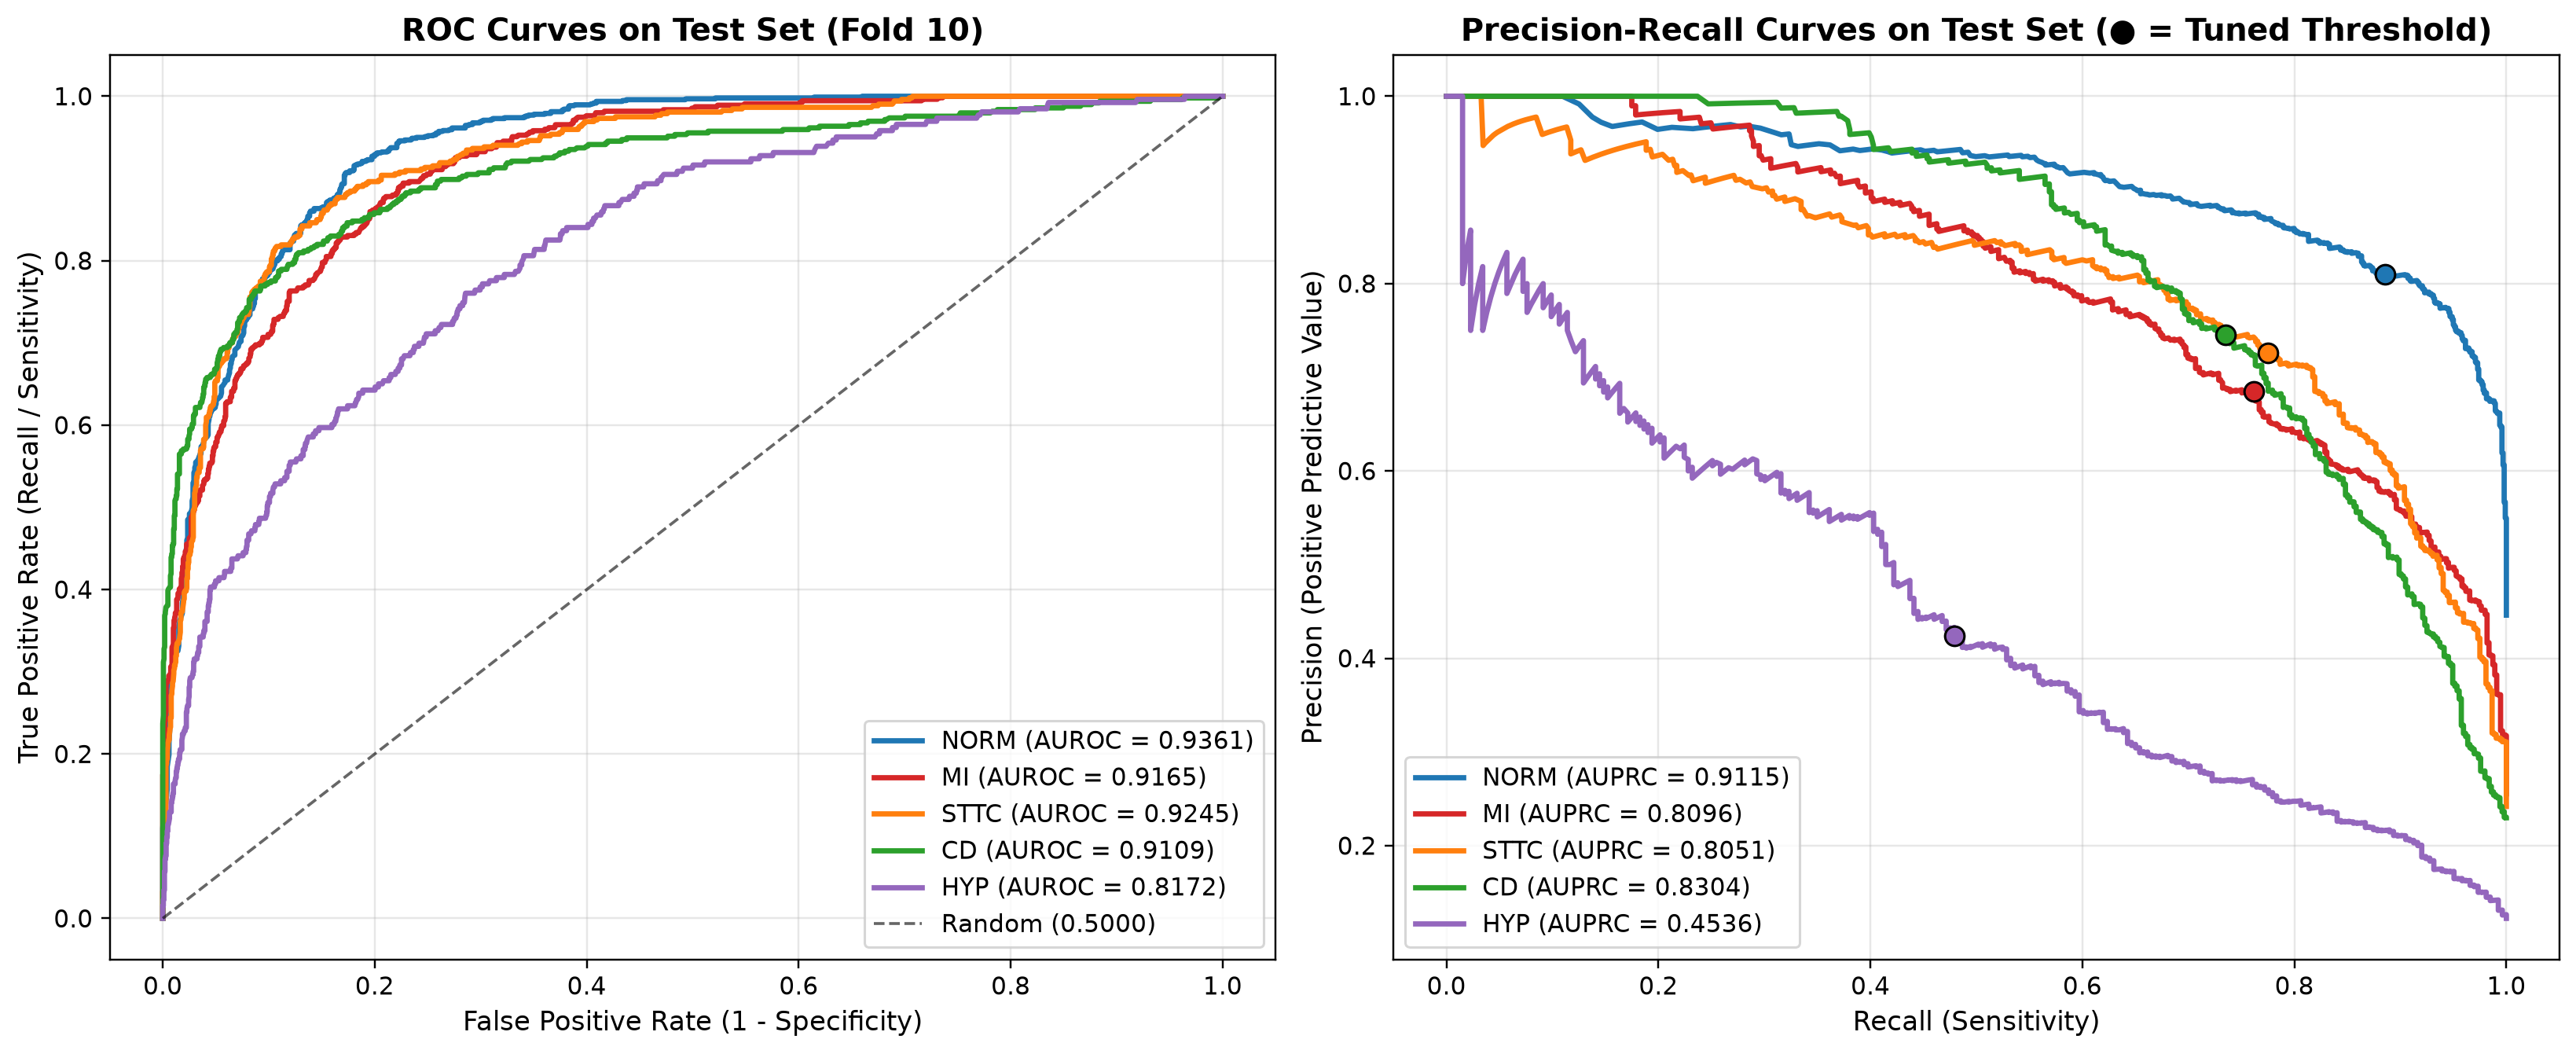

In [3]:
colors = {'NORM': '#1f77b4', 'MI': '#d62728', 'STTC': '#ff7f0e', 'CD': '#2ca02c', 'HYP': '#9467bd'}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))

# 1. ROC Curves
ax_roc = axes[0]
for idx, label in enumerate(SUPERCLASSES):
    fpr, tpr, _ = roc_curve(y_true_test[:, idx], y_prob_test[:, idx])
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=colors[label], lw=2.2, label=f'{label} (AUROC = {roc_auc:.4f})')

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.6, label='Random (0.5000)')
ax_roc.set_title('ROC Curves on Test Set (Fold 10)', fontsize=13, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax_roc.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax_roc.legend(loc='lower right', frameon=True, fontsize=10)
ax_roc.grid(True, alpha=0.3)

# 2. Precision-Recall Curves
ax_pr = axes[1]
for idx, label in enumerate(SUPERCLASSES):
    precision_c, recall_c, _ = precision_recall_curve(y_true_test[:, idx], y_prob_test[:, idx])
    ap = average_precision_score(y_true_test[:, idx], y_prob_test[:, idx])
    ax_pr.plot(recall_c, precision_c, color=colors[label], lw=2.2, label=f'{label} (AUPRC = {ap:.4f})')
    # Đánh dấu điểm ngưỡng tối ưu
    pred_c = y_pred_tuned[:, idx]
    tp = np.sum((pred_c == 1) & (y_true_test[:, idx] == 1))
    fp = np.sum((pred_c == 1) & (y_true_test[:, idx] == 0))
    fn = np.sum((pred_c == 0) & (y_true_test[:, idx] == 1))
    pt_rec = tp / max(tp + fn, 1)
    pt_prec = tp / max(tp + fp, 1)
    ax_pr.scatter([pt_rec], [pt_prec], color=colors[label], edgecolors='black', s=65, zorder=5)

ax_pr.set_title('Precision-Recall Curves on Test Set (● = Tuned Threshold)', fontsize=13, fontweight='bold')
ax_pr.set_xlabel('Recall (Sensitivity)', fontsize=11)
ax_pr.set_ylabel('Precision (Positive Predictive Value)', fontsize=11)
ax_pr.legend(loc='lower left', frameon=True, fontsize=10)
ax_pr.grid(True, alpha=0.3)

plt.tight_layout()
roc_pr_path = figures_dir / 'test_roc_pr_curves.png'
fig.savefig(roc_pr_path, bbox_inches='tight')
plt.show()
print('Saved figure:', roc_pr_path)

## 4. Bộ 5 Ma trận nhầm lẫn đa nhãn (`Multilabel Confusion Matrices` $2 \times 2$)

So sánh trực tiếp 5 ma trận nhầm lẫn của 5 nhóm bệnh trên tập Test:
- **Hàng trên:** Ngưỡng cố định $\tau = 0.5$.
- **Hàng dưới:** Sau khi tối ưu ngưỡng (Kịch bản B, giữ `CD = 0.5`) — cho thấy số ca bỏ sót bệnh (**FN**, ô dưới bên trái) giảm mạnh ở `MI` (từ `260` $\rightarrow$ `126`) và `HYP` (từ `181` $\rightarrow$ `137`).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\test_multilabel_confusion_matrices.png


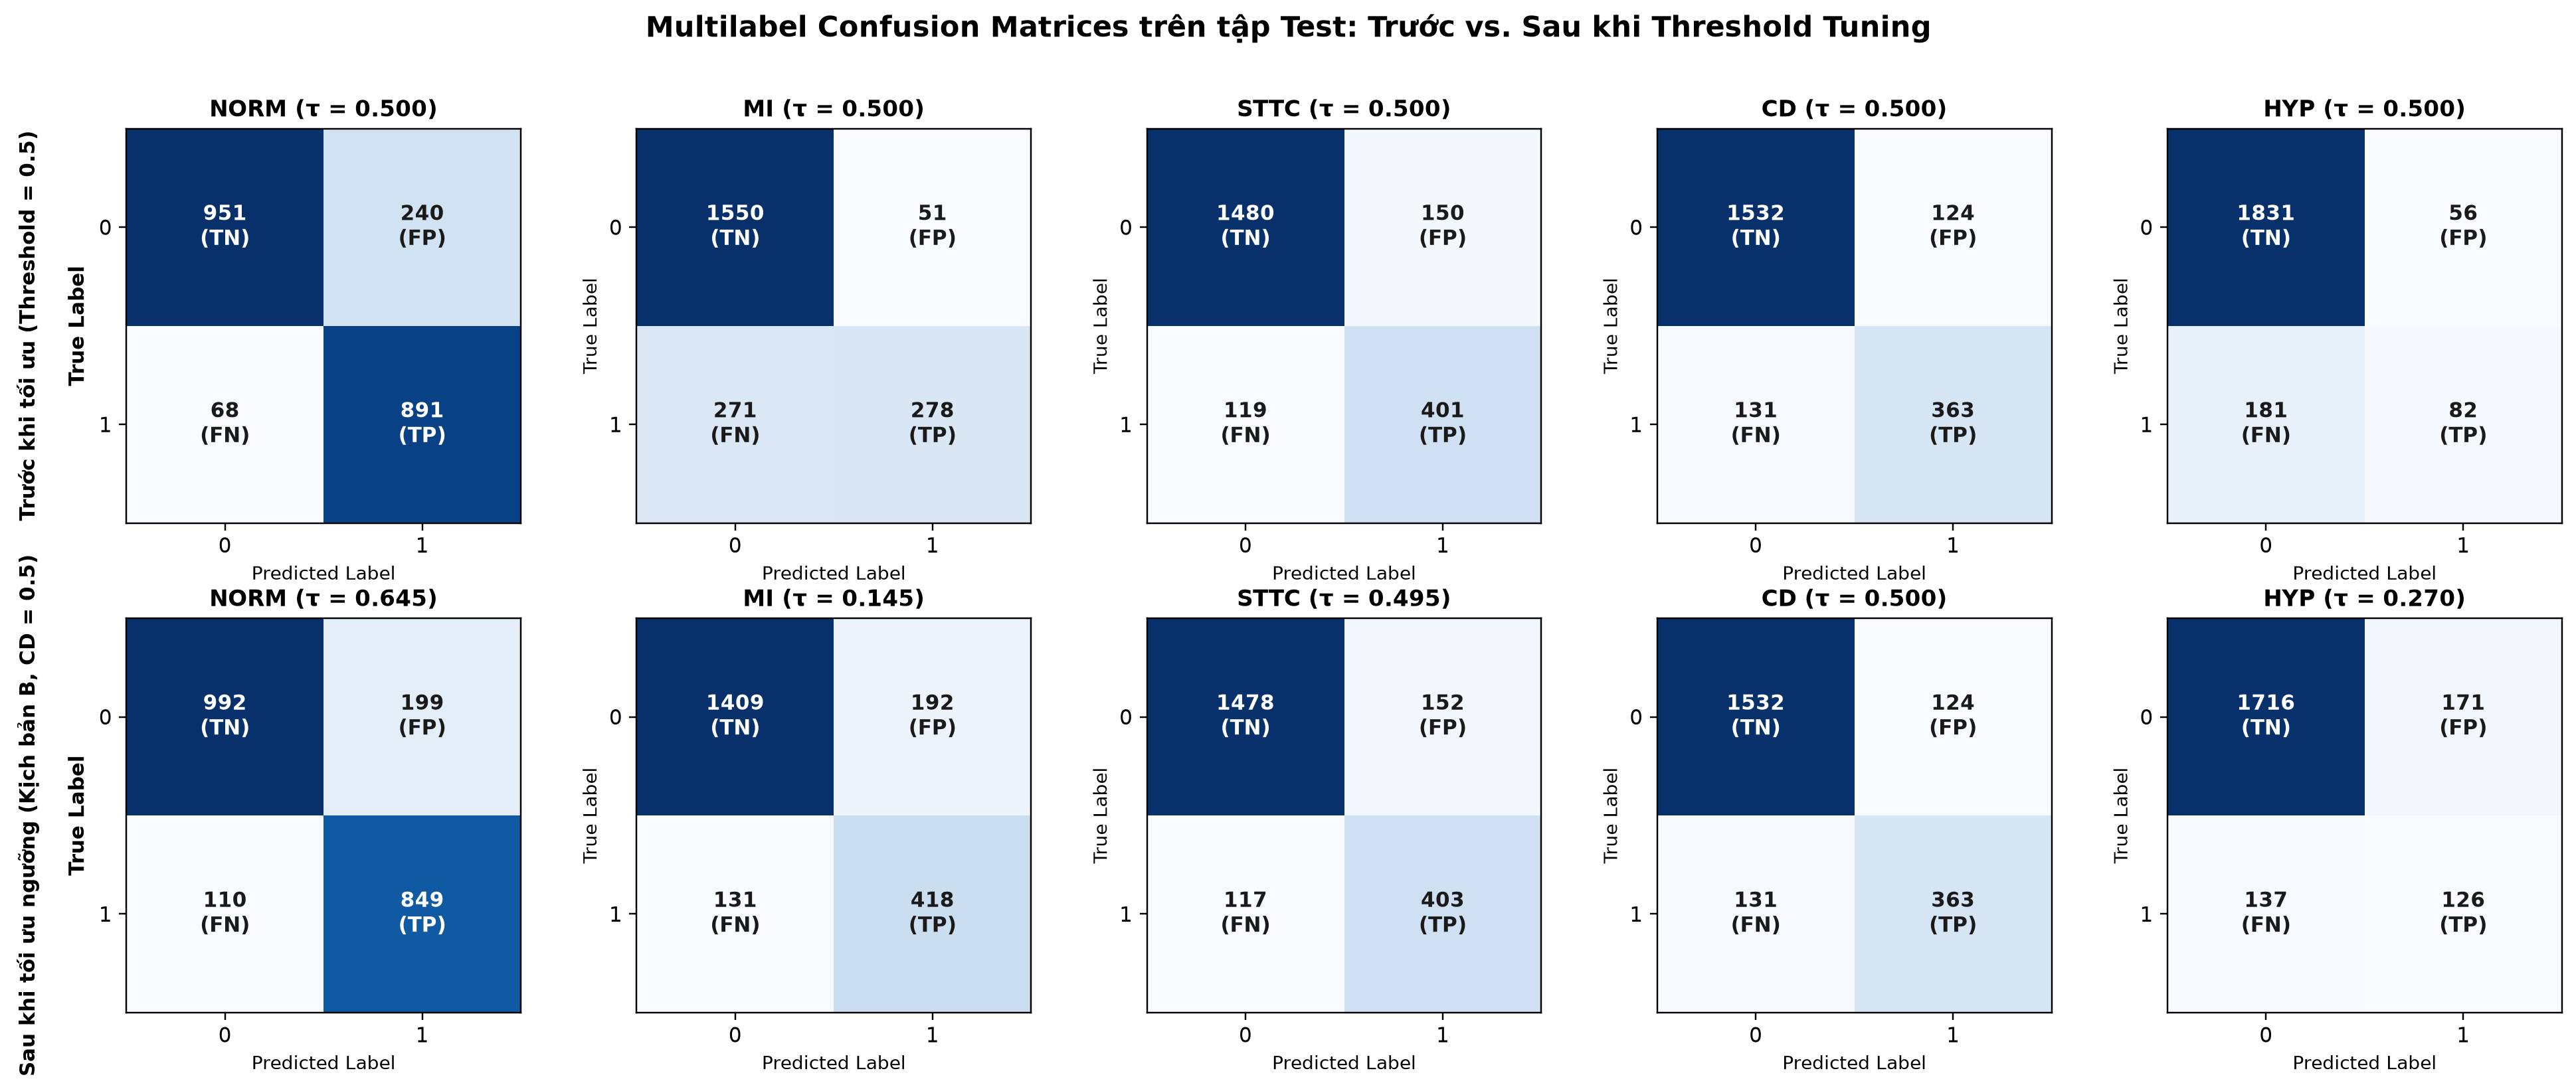

In [4]:
mcm_default = multilabel_confusion_matrix(y_true_test, y_pred_default)
mcm_tuned = multilabel_confusion_matrix(y_true_test, y_pred_tuned)

fig, axes = plt.subplots(2, 5, figsize=(18, 7.2))

for row_idx, (mcm, row_title, thresh_info) in enumerate([
    (mcm_default, 'Trước khi tối ưu (Threshold = 0.5)', {label: 0.5 for label in SUPERCLASSES}),
    (mcm_tuned, 'Sau khi tối ưu ngưỡng (Kịch bản B, CD = 0.5)', tuned_thresholds),
]):
    for col_idx, label in enumerate(SUPERCLASSES):
        ax = axes[row_idx, col_idx]
        cm = mcm[col_idx]
        im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
        ax.set_title(f'{label} (τ = {thresh_info[label]:.3f})', fontsize=11, fontweight='bold')
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(['0', '1'])
        ax.set_yticklabels(['0', '1'])
        if col_idx == 0:
            ax.set_ylabel(f'{row_title}\n\nTrue Label', fontsize=10, fontweight='bold')
        else:
            ax.set_ylabel('True Label', fontsize=9)
        ax.set_xlabel('Predicted Label', fontsize=9)

        thresh_color = cm.max() / 2.0
        tag_names = [['TN', 'FP'], ['FN', 'TP']]
        for i in range(2):
            for j in range(2):
                val = int(cm[i, j])
                ax.text(
                    j, i, f'{val}\n({tag_names[i][j]})',
                    ha='center', va='center', fontsize=10, fontweight='bold',
                    color='white' if val > thresh_color else '#1a1a1a',
                )

fig.suptitle('Multilabel Confusion Matrices trên tập Test: Trước vs. Sau khi Threshold Tuning', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
cm_path = figures_dir / 'test_multilabel_confusion_matrices.png'
fig.savefig(cm_path, bbox_inches='tight')
plt.show()
print('Saved figure:', cm_path)

## 5. Ma trận Đồng xuất hiện 5 nhóm bệnh lý (`Disease Co-occurrence Heatmap` $5 \times 5$)

Trực quan hóa sự chồng lấp đa nhãn giữa 5 superclass trên toàn bộ dữ liệu để minh họa bản chất Multi-label (tương tự Slide 9 của nhóm kỳ trước).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\superclass_cooccurrence_heatmap.png


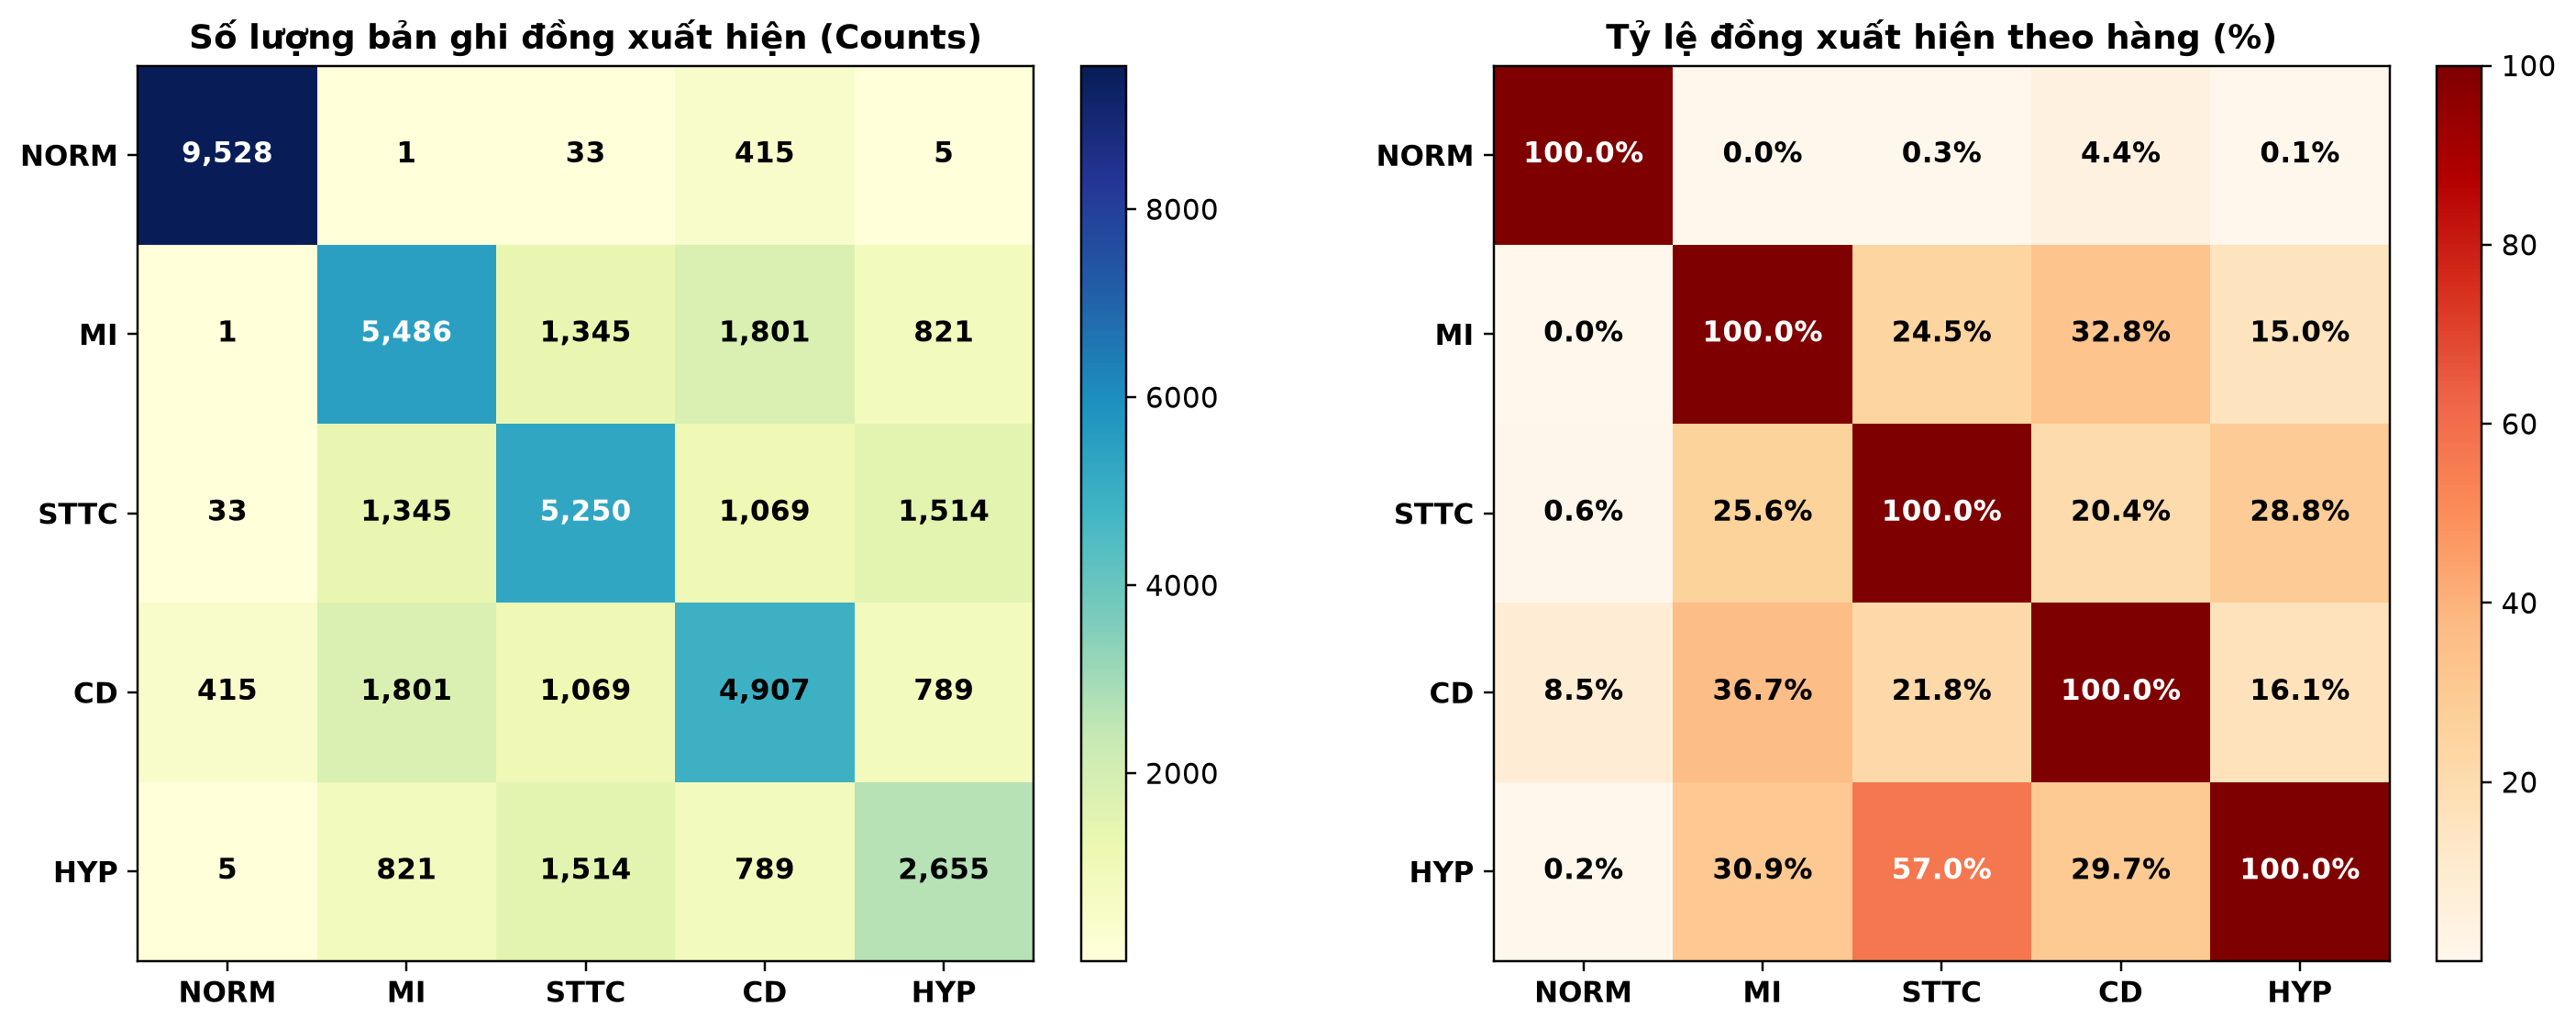

In [5]:
label_mat = signal_index[list(SUPERCLASSES)].to_numpy(dtype=np.int64)
coocc_counts = label_mat.T @ label_mat
diag_counts = np.diag(coocc_counts).astype(np.float64)
coocc_pct = (coocc_counts / diag_counts[:, np.newaxis]) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

for ax, matrix, title, fmt_fn, cmap in [
    (axes[0], coocc_counts, 'Số lượng bản ghi đồng xuất hiện (Counts)', lambda v: f'{int(v):,}', 'YlGnBu'),
    (axes[1], coocc_pct, 'Tỷ lệ đồng xuất hiện theo hàng (%)', lambda v: f'{v:.1f}%', 'OrRd'),
]:
    im = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(len(SUPERCLASSES)))
    ax.set_yticks(range(len(SUPERCLASSES)))
    ax.set_xticklabels(SUPERCLASSES, fontweight='bold')
    ax.set_yticklabels(SUPERCLASSES, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    thresh_val = matrix.max() * 0.55
    for i in range(len(SUPERCLASSES)):
        for j in range(len(SUPERCLASSES)):
            ax.text(
                j, i, fmt_fn(matrix[i, j]),
                ha='center', va='center', fontsize=10, fontweight='bold',
                color='white' if matrix[i, j] > thresh_val else 'black',
            )
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
coocc_path = figures_dir / 'superclass_cooccurrence_heatmap.png'
fig.savefig(coocc_path, bbox_inches='tight')
plt.show()
print('Saved figure:', coocc_path)

## 6. Giải thích mô hình với 1D Grad-CAM cho 10 ca `NORM` điển hình

- Tính **1D Grad-CAM** tại tầng trích xuất đặc trưng tích chập đa tỷ lệ (`model.inception`) cho từng bản ghi.
- Vẽ 10 bản ghi `NORM` trên tập Test với độ tự tin cao (tương tự mục **7.6 Grad-CAM for 10 NORMs** của nhóm kỳ trước).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\gradcam_10_norm_cases.png


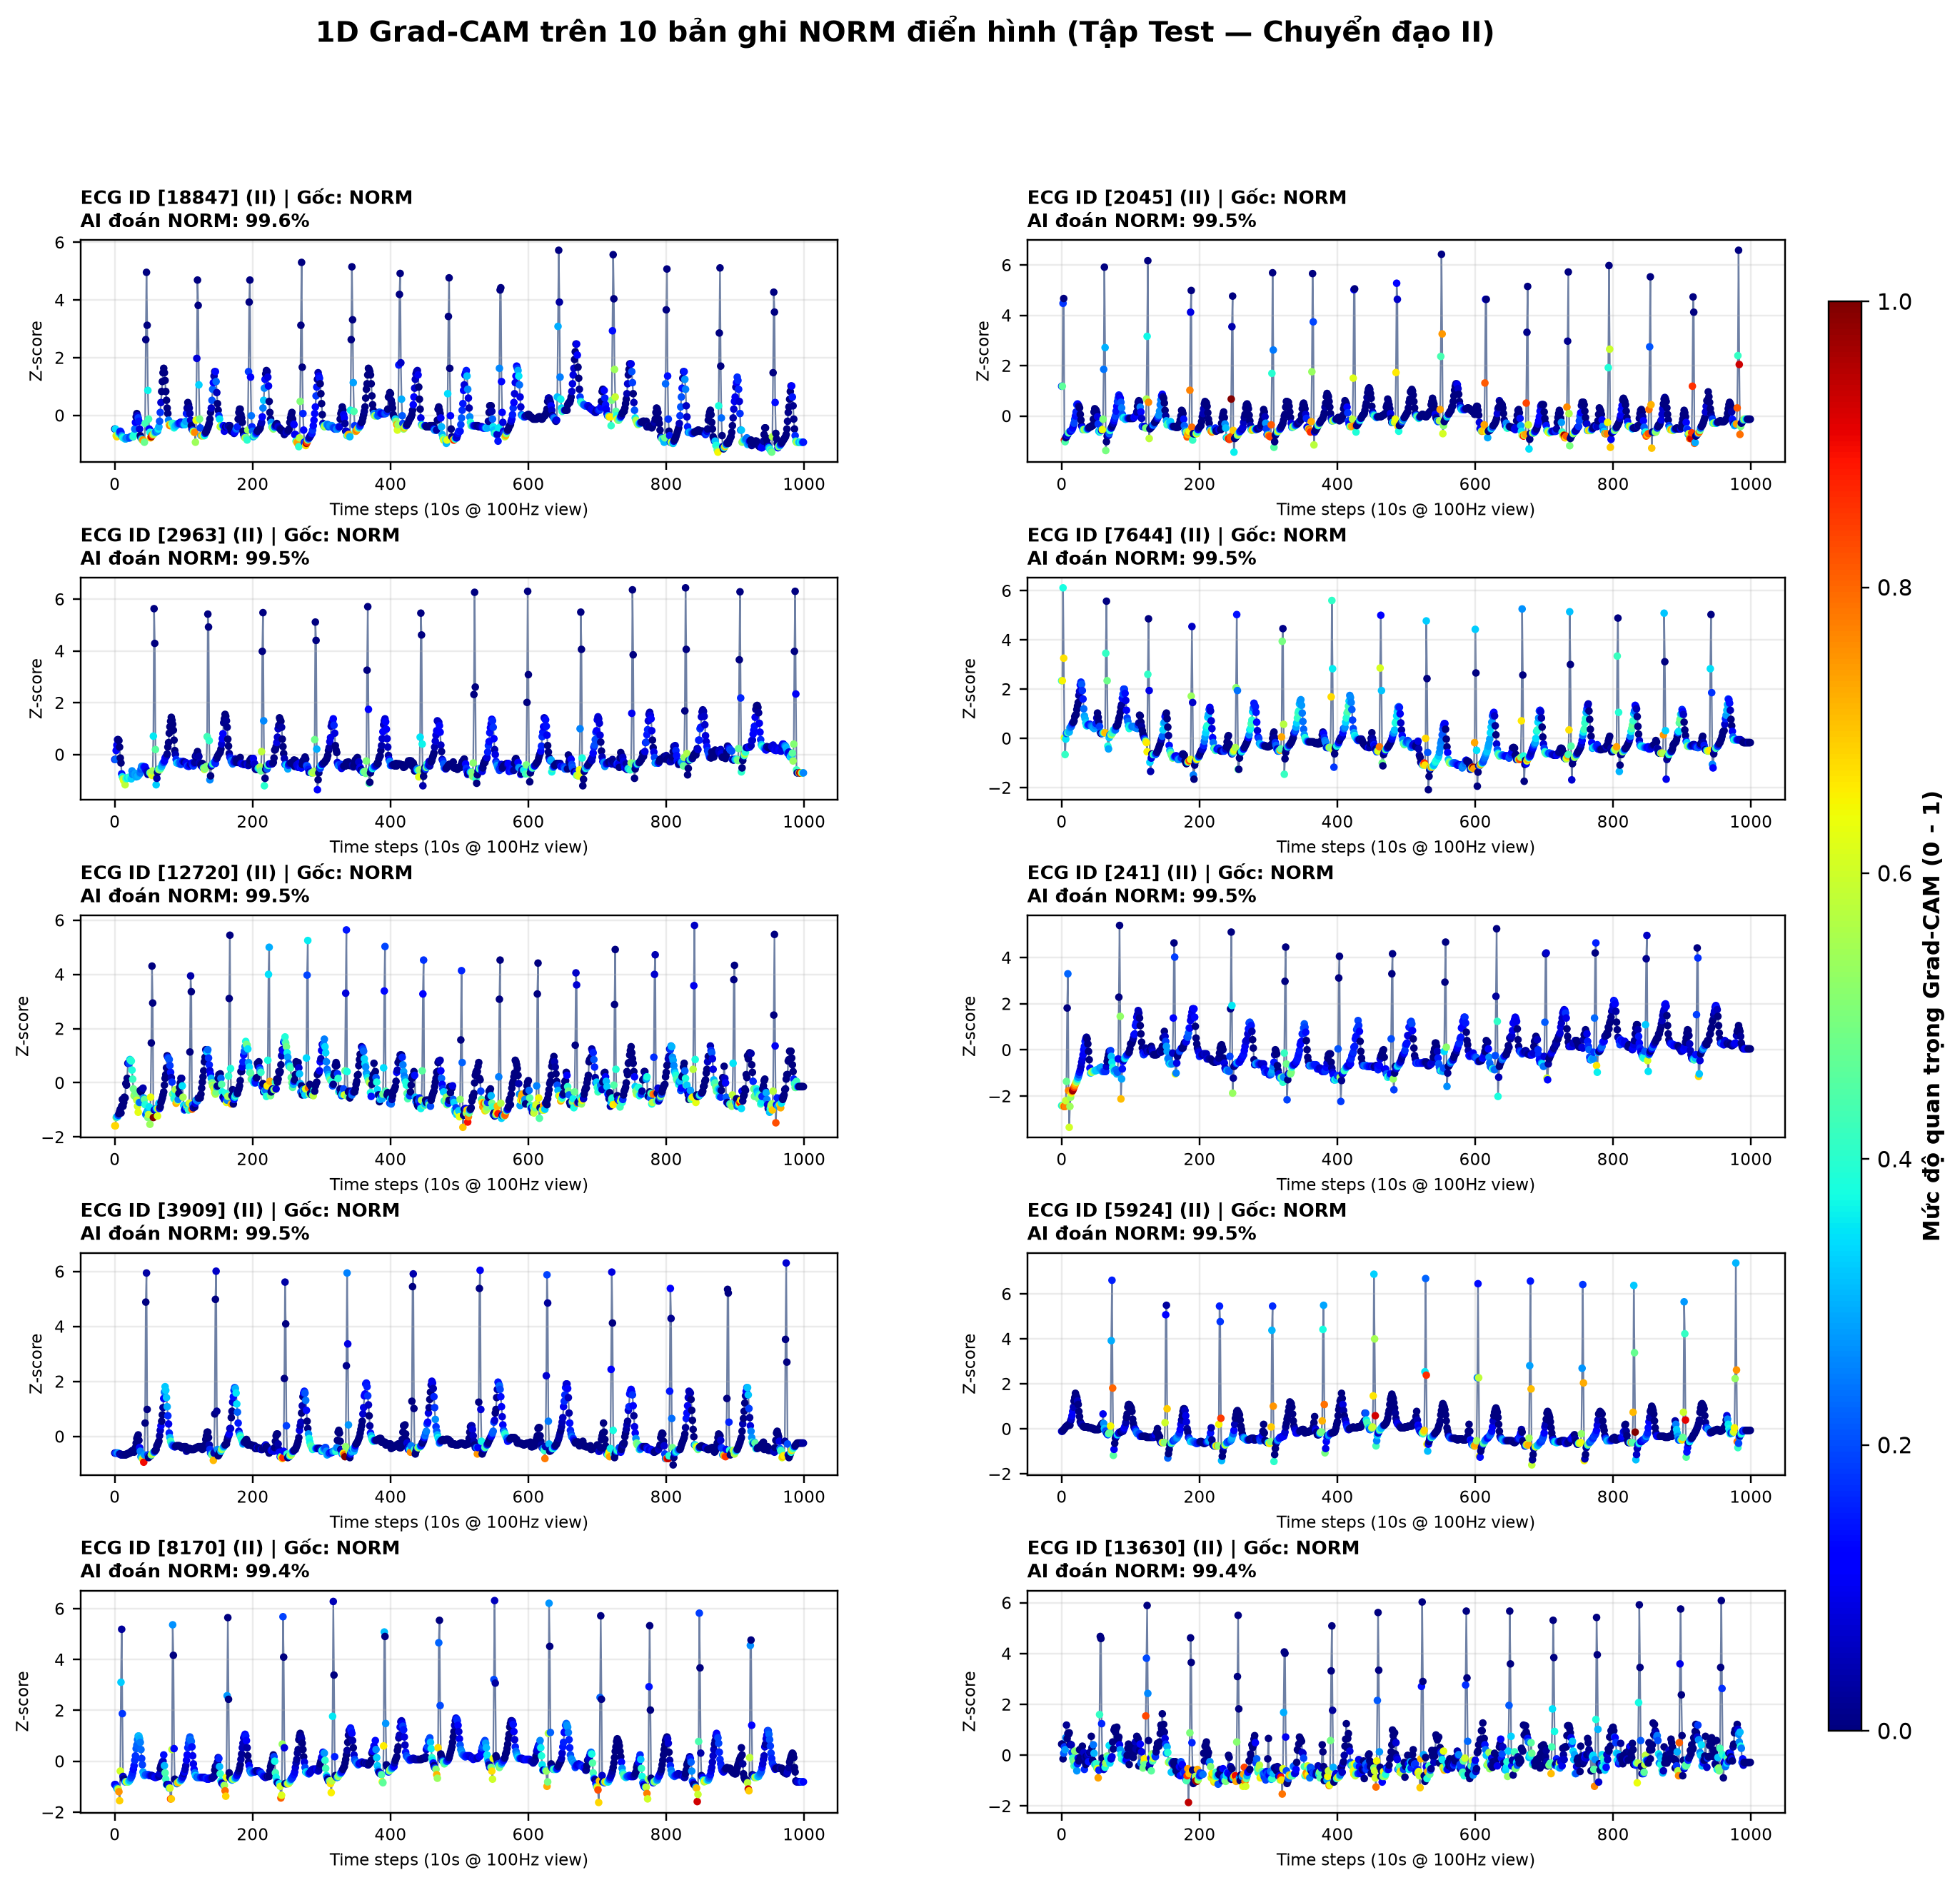

In [6]:
STANDARD_LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

def compute_1d_gradcam(model, ecg_tensor, clinical_tensor, target_class_idx):
    """Compute 1D Grad-CAM (length 5000) and predicted probabilities for one ECG record."""
    activations = []
    gradients = []

    def forward_hook(_module, _inp, out):
        activations.append(out)

    def backward_hook(_module, _grad_in, grad_out):
        gradients.append(grad_out[0])

    handle_f = model.inception.register_forward_hook(forward_hook)
    handle_b = model.inception.register_full_backward_hook(backward_hook)
    try:
        model.zero_grad(set_to_none=True)
        with torch.backends.cudnn.flags(enabled=False):
            logits = model(ecg_tensor, clinical_tensor)
            probs = torch.sigmoid(logits).detach().cpu().numpy()[0]
            score = logits[0, target_class_idx]
            score.backward()

        act = activations[0].detach()[0]   # (C, 5000)
        grad = gradients[0].detach()[0]    # (C, 5000)
        weights = grad.mean(dim=-1, keepdim=True)  # (C, 1)
        cam = torch.relu((weights * act).sum(dim=0)).cpu().numpy()
        cam_min, cam_max = float(cam.min()), float(cam.max())
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)
        return cam, probs
    finally:
        handle_f.remove()
        handle_b.remove()


def plot_gradcam_grid(sample_indices, target_class_indices, lead_indices, nrows, ncols, figsize, suptitle, save_path):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes_flat = np.asarray(axes).reshape(-1)
    scatter_ref = None

    for plot_idx, (ds_idx, cls_idx, lead_idx) in enumerate(zip(sample_indices, target_class_indices, lead_indices)):
        ax = axes_flat[plot_idx]
        item = test_dataset[int(ds_idx)]
        ecg_batch = item['ecg'].unsqueeze(0).to(device)
        clin_batch = item['clinical'].unsqueeze(0).to(device)
        ecg_id = int(item['ecg_id'].item())
        true_vec = item['target'].numpy().astype(int)
        true_labels = [SUPERCLASSES[i] for i, v in enumerate(true_vec) if v == 1]

        cam, probs = compute_1d_gradcam(model, ecg_batch, clin_batch, int(cls_idx))
        # Downsample mỗi 5 mẫu (1000 điểm trên 10 giây) để vẽ điểm nhiệt rõ nét giống slide mẫu
        step = 5
        t_steps = np.arange(0, 5000, step) // step
        sig_lead = item['ecg'].numpy()[lead_idx, ::step]
        cam_sub = cam[::step]

        ax.plot(t_steps, sig_lead, color='#1f3b73', lw=0.75, alpha=0.65, zorder=1)
        scatter_ref = ax.scatter(
            t_steps, sig_lead, c=cam_sub, cmap='jet', vmin=0.0, vmax=1.0, s=6, zorder=2
        )
        cls_name = SUPERCLASSES[cls_idx]
        lead_name = STANDARD_LEADS[lead_idx]
        ax.set_title(
            f'ECG ID [{ecg_id}] ({lead_name}) | Gốc: {", ".join(true_labels)}\n'
            f'AI đoán {cls_name}: {probs[cls_idx] * 100:.1f}%',
            fontsize=8.5, fontweight='bold', loc='left',
        )
        ax.set_xlabel('Time steps (10s @ 100Hz view)', fontsize=7.5)
        ax.set_ylabel('Z-score', fontsize=7.5)
        ax.tick_params(labelsize=7.5)
        ax.grid(True, alpha=0.25)

    fig.subplots_adjust(right=0.90, hspace=0.52, wspace=0.25)
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
    cbar = fig.colorbar(scatter_ref, cax=cbar_ax)
    cbar.set_label('Mức độ quan trọng Grad-CAM (0 - 1)', fontsize=10, fontweight='bold')
    fig.suptitle(suptitle, fontsize=13, fontweight='bold', y=0.99)
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()
    print('Saved figure:', save_path)


# Chọn 10 ca thuần NORM có xác suất dự đoán cao nhất trên tập Test
pure_norm_mask = (y_true_test[:, 0] == 1) & (y_true_test[:, 1:].sum(axis=1) == 0)
norm_candidates = np.where(pure_norm_mask)[0]
top10_norm_indices = norm_candidates[np.argsort(-y_prob_test[norm_candidates, 0])[:10]]

plot_gradcam_grid(
    sample_indices=top10_norm_indices,
    target_class_indices=[0] * 10,
    lead_indices=[1] * 10,  # Chuyển đạo II chuẩn lâm sàng
    nrows=5,
    ncols=2,
    figsize=(14, 13),
    suptitle='1D Grad-CAM trên 10 bản ghi NORM điển hình (Tập Test — Chuyển đạo II)',
    save_path=figures_dir / 'gradcam_10_norm_cases.png',
)

## 7. Giải thích 1D Grad-CAM cho các ca Bệnh lý (`MI`, `STTC`, `CD`, `HYP` & Đa nhãn)

Trực quan hóa 12 ca bệnh lý điển hình (3 ca cho mỗi nhóm `MI`, `STTC`, `CD`, `HYP`, bao gồm cả các ca đa nhãn) trên chuyển đạo đặc trưng để đối chiếu với hình thái sóng P-QRS-T lâm sàng.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\gradcam_disease_cases.png


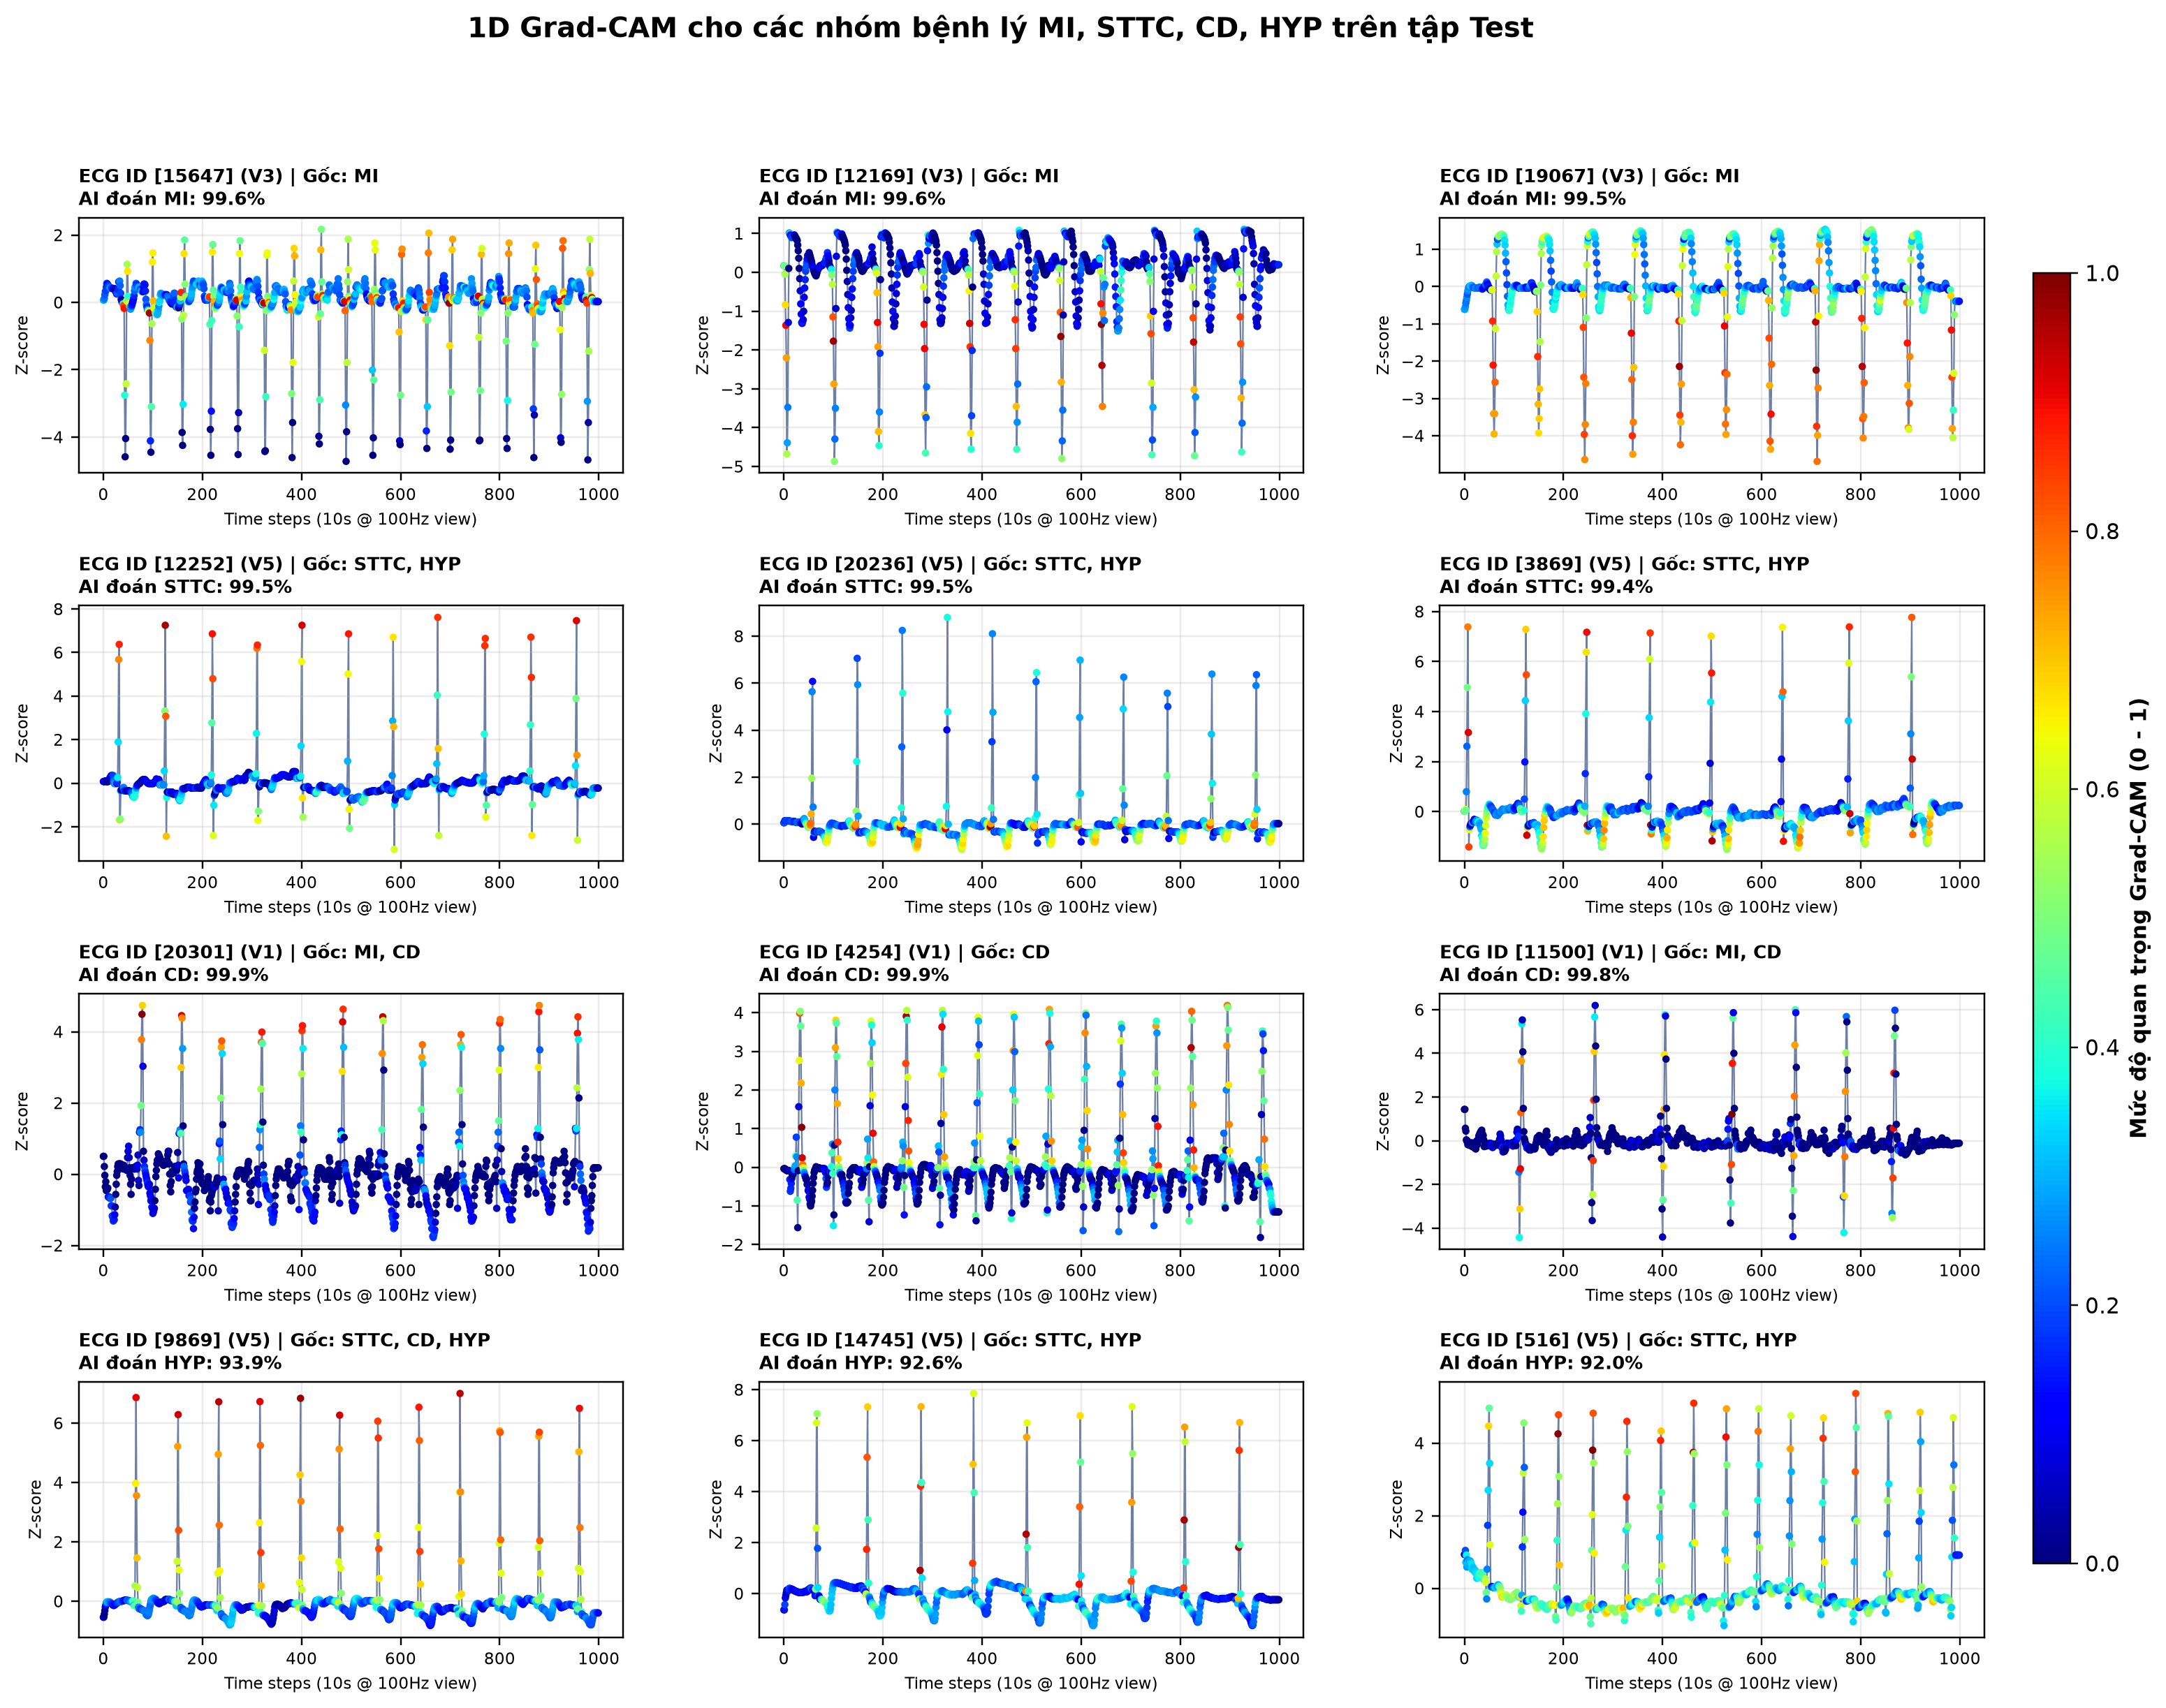

In [7]:
disease_indices = []
disease_cls = []
disease_leads = []

# Chọn chuyển đạo đại diện rõ hình thái nhất cho từng bệnh: MI -> V3, STTC -> V5, CD -> V1, HYP -> V5
preferred_lead_by_cls = {1: 8, 2: 10, 3: 6, 4: 10}
for cls_idx in (1, 2, 3, 4):
    pos_mask = y_true_test[:, cls_idx] == 1
    pos_candidates = np.where(pos_mask)[0]
    top3 = pos_candidates[np.argsort(-y_prob_test[pos_candidates, cls_idx])[:3]]
    for idx_val in top3:
        disease_indices.append(int(idx_val))
        disease_cls.append(cls_idx)
        disease_leads.append(preferred_lead_by_cls[cls_idx])

plot_gradcam_grid(
    sample_indices=disease_indices,
    target_class_indices=disease_cls,
    lead_indices=disease_leads,
    nrows=4,
    ncols=3,
    figsize=(16, 12),
    suptitle='1D Grad-CAM cho các nhóm bệnh lý MI, STTC, CD, HYP trên tập Test',
    save_path=figures_dir / 'gradcam_disease_cases.png',
)

## 8. Ma trận Đóng góp của 12 Chuyển đạo ($12 \times 5$ Heatmap) & Đóng góp Đa phương thức (`ECG` vs. `Clinical`)

1. **Ma trận Saliency $12 \times 5$ (12 Leads $\times$ 5 Superclasses):** Tính trung bình độ lớn đạo hàm theo đầu vào $\left|\frac{\partial \text{logit}_c}{\partial X_{l, t}}\right|$ trên các ca dương tính của tập Test để xác định chuyển đạo nào đóng vai trò quyết định cho từng nhóm bệnh.
2. **Phân tích đóng góp Đa phương thức (Late Fusion Contribution):** So sánh tỷ trọng đóng góp vào logit dự đoán giữa nhánh `ECG Embedding (192 chiều)` và nhánh `Clinical Embedding [age_z, sex] (16 chiều)`.

=== MA TRẬN TỶ TRỌNG ĐÓNG GÓP CỦA 12 CHUYỂN ĐẠO THEO TỪNG NHÓM BỆNH (%) ===
      NORM     MI   STTC     CD    HYP
I    8.32%  8.83%  9.38%  8.93%  8.80%
II   7.55%  8.47%  8.00%  8.37%  8.20%
III  6.21%  6.57%  6.33%  6.66%  6.09%
aVR  8.68%  8.24%  8.91%  8.55%  9.31%
aVL  7.42%  7.66%  7.72%  7.79%  7.37%
aVF  8.53%  8.87%  8.08%  8.35%  8.48%
V1  11.76% 10.69% 10.92% 10.71% 11.25%
V2   8.99%  9.48%  9.09%  9.24%  9.03%
V3   7.08%  7.30%  7.01%  7.13%  6.93%
V4   8.01%  7.68%  7.66%  7.65%  7.37%
V5   7.80%  7.40%  7.45%  7.71%  7.63%
V6   9.64%  8.81%  9.46%  8.91%  9.55%

=== BẢNG TỶ TRỌNG ĐÓNG GÓP ĐA PHƯƠNG THỨC (LATE FUSION: ECG vs. CLINICAL) ===
      ECG Waveform Share (%)  Clinical [age_z, sex] Share (%)
NORM                  94.73%                            5.27%
MI                    95.00%                            5.00%
STTC                  96.45%                            3.55%
CD                    97.84%                            2.16%
HYP                   97.08%

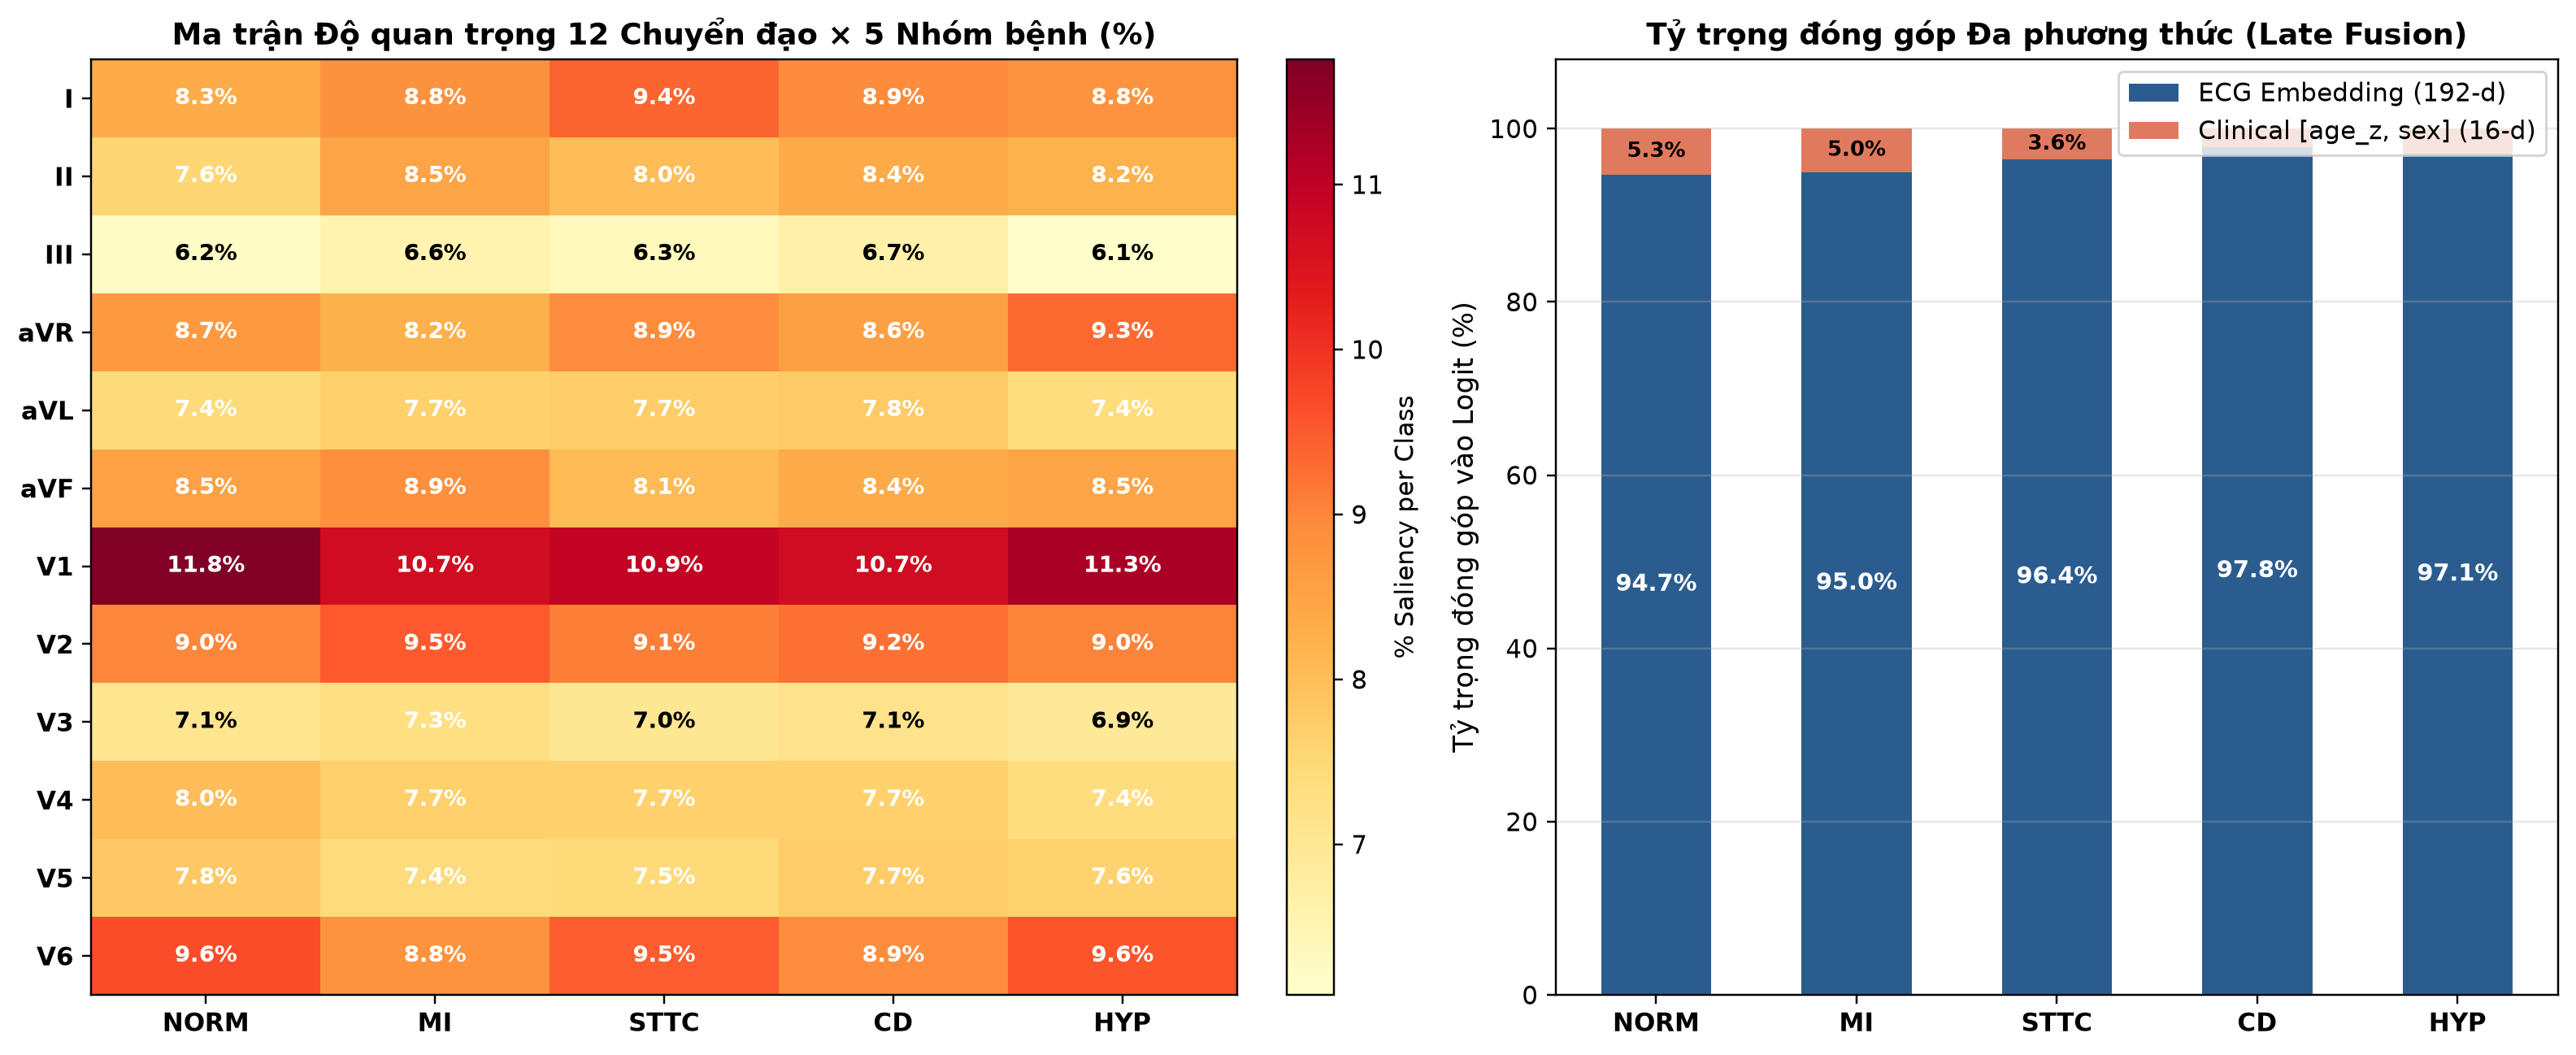

In [8]:
# 1. Tính Ma trận độ quan trọng 12 chuyển đạo x 5 nhóm bệnh bằng Input Gradient Saliency
lead_saliency_matrix = np.zeros((12, len(SUPERCLASSES)), dtype=np.float64)

for cls_idx, label in enumerate(SUPERCLASSES):
    pos_indices = np.where(y_true_test[:, cls_idx] == 1)[0]
    # Lấy tối đa 80 ca dương tính có xác suất cao nhất của mỗi lớp để tính trung bình đại diện
    selected = pos_indices[np.argsort(-y_prob_test[pos_indices, cls_idx])[:80]]
    ecg_batch = torch.stack([test_dataset[int(i)]['ecg'] for i in selected]).to(device)
    clin_batch = torch.stack([test_dataset[int(i)]['clinical'] for i in selected]).to(device)
    ecg_batch.requires_grad_(True)

    model.zero_grad(set_to_none=True)
    with torch.backends.cudnn.flags(enabled=False):
        logits = model(ecg_batch, clin_batch)
        logits[:, cls_idx].sum().backward()

    grad_abs = ecg_batch.grad.detach().abs().mean(dim=(0, 2)).cpu().numpy()  # (12,)
    lead_saliency_matrix[:, cls_idx] = grad_abs / grad_abs.sum() * 100.0

lead_saliency_df = pd.DataFrame(lead_saliency_matrix, index=STANDARD_LEADS, columns=SUPERCLASSES)
print('=== MA TRẬN TỶ TRỌNG ĐÓNG GÓP CỦA 12 CHUYỂN ĐẠO THEO TỪNG NHÓM BỆNH (%) ===')
print(lead_saliency_df.to_string(float_format=lambda v: f'{v:.2f}%'))

# 2. Tính tỷ trọng đóng góp giữa ECG Embedding (192 chiều) và Clinical Embedding (16 chiều)
w_ecg = model.classifier.weight[:, :192].detach()   # (5, 192)
w_clin = model.classifier.weight[:, 192:].detach()  # (5, 16)

ecg_contrib_list = []
clin_contrib_list = []
with torch.inference_mode():
    for batch in test_loader:
        ecg_b = batch['ecg'].to(device)
        clin_b = batch['clinical'].to(device)
        feat = model.downsample(model.inception(model.stem(ecg_b)))
        seq = model.sequence_model(feat.transpose(1, 2))
        z_ecg = model.attention_pool(seq)          # (B, 192)
        z_clin = model.clinical_encoder(clin_b)    # (B, 16)

        c_ecg = torch.matmul(z_ecg, w_ecg.T).abs().cpu().numpy()    # (B, 5)
        c_clin = torch.matmul(z_clin, w_clin.T).abs().cpu().numpy() # (B, 5)
        ecg_contrib_list.append(c_ecg)
        clin_contrib_list.append(c_clin)

ecg_contrib_all = np.concatenate(ecg_contrib_list, axis=0).mean(axis=0)
clin_contrib_all = np.concatenate(clin_contrib_list, axis=0).mean(axis=0)
total_contrib = ecg_contrib_all + clin_contrib_all
ecg_share = (ecg_contrib_all / total_contrib) * 100.0
clin_share = (clin_contrib_all / total_contrib) * 100.0

multimodal_df = pd.DataFrame({
    'ECG Waveform Share (%)': ecg_share,
    'Clinical [age_z, sex] Share (%)': clin_share,
}, index=SUPERCLASSES)
print('\n=== BẢNG TỶ TRỌNG ĐÓNG GÓP ĐA PHƯƠNG THỨC (LATE FUSION: ECG vs. CLINICAL) ===')
print(multimodal_df.to_string(float_format=lambda v: f'{v:.2f}%'))

# Vẽ chung 2 biểu đồ XAI cấp toàn cục (12x5 Lead Heatmap + Multimodal Bar Chart)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), gridspec_kw={'width_ratios': [1.25, 1.0]})

ax0 = axes[0]
im = ax0.imshow(lead_saliency_matrix, cmap='YlOrRd', aspect='auto')
ax0.set_xticks(range(len(SUPERCLASSES)))
ax0.set_yticks(range(len(STANDARD_LEADS)))
ax0.set_xticklabels(SUPERCLASSES, fontweight='bold')
ax0.set_yticklabels(STANDARD_LEADS, fontweight='bold')
ax0.set_title('Ma trận Độ quan trọng 12 Chuyển đạo × 5 Nhóm bệnh (%)', fontsize=12, fontweight='bold')
for i in range(12):
    for j in range(len(SUPERCLASSES)):
        val = lead_saliency_matrix[i, j]
        ax0.text(
            j, i, f'{val:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if val > lead_saliency_matrix.max() * 0.62 else 'black',
        )
fig.colorbar(im, ax=ax0, fraction=0.046, pad=0.04, label='% Saliency per Class')

ax1 = axes[1]
x_pos = np.arange(len(SUPERCLASSES))
bars1 = ax1.bar(x_pos, ecg_share, width=0.55, label='ECG Embedding (192-d)', color='#2b5c8f')
bars2 = ax1.bar(x_pos, clin_share, width=0.55, bottom=ecg_share, label='Clinical [age_z, sex] (16-d)', color='#e07a5f')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(SUPERCLASSES, fontweight='bold')
ax1.set_ylim(0, 108)
ax1.set_ylabel('Tỷ trọng đóng góp vào Logit (%)', fontsize=11)
ax1.set_title('Tỷ trọng đóng góp Đa phương thức (Late Fusion)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(axis='y', alpha=0.3)
for idx, (e_val, c_val) in enumerate(zip(ecg_share, clin_share)):
    ax1.text(idx, e_val / 2, f'{e_val:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
    if c_val >= 3.0:
        ax1.text(idx, e_val + c_val / 2, f'{c_val:.1f}%', ha='center', va='center', color='black', fontweight='bold', fontsize=8.5)

plt.tight_layout()
xai_matrix_path = figures_dir / 'xai_lead_importance_and_multimodal.png'
fig.savefig(xai_matrix_path, bbox_inches='tight')
plt.show()
print('Saved figure:', xai_matrix_path)

## 9. Hiệu chuẩn Xác suất (`Calibration Curve / Reliability Diagram`, `ECE` & `Brier Score`)

Trong hỗ trợ quyết định lâm sàng, bác sĩ sử dụng **xác suất dự báo** chứ không chỉ nhãn nhị phân 0/1. Mục này đánh giá độ tin cậy xác suất cho từng nhóm bệnh trên tập Test (`Fold 10`) bằng **Expected Calibration Error (ECE — 10 bins)**, **Brier Score** và **Reliability Diagram** (`calibration_curve`).

=== BẢNG ĐÁNH GIÁ HIỆU CHUẨN XÁC SUẤT (CALIBRATION) TRÊN TẬP TEST (FOLD 10) ===
        Class  ECE (10 bins)  Brier Score
         NORM         0.0647       0.1082
           MI         0.0750       0.1110
         STTC         0.0412       0.0923
           CD         0.0401       0.0895
          HYP         0.0283       0.0870
Macro Average         0.0499       0.0976
Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\test_calibration_curves.png


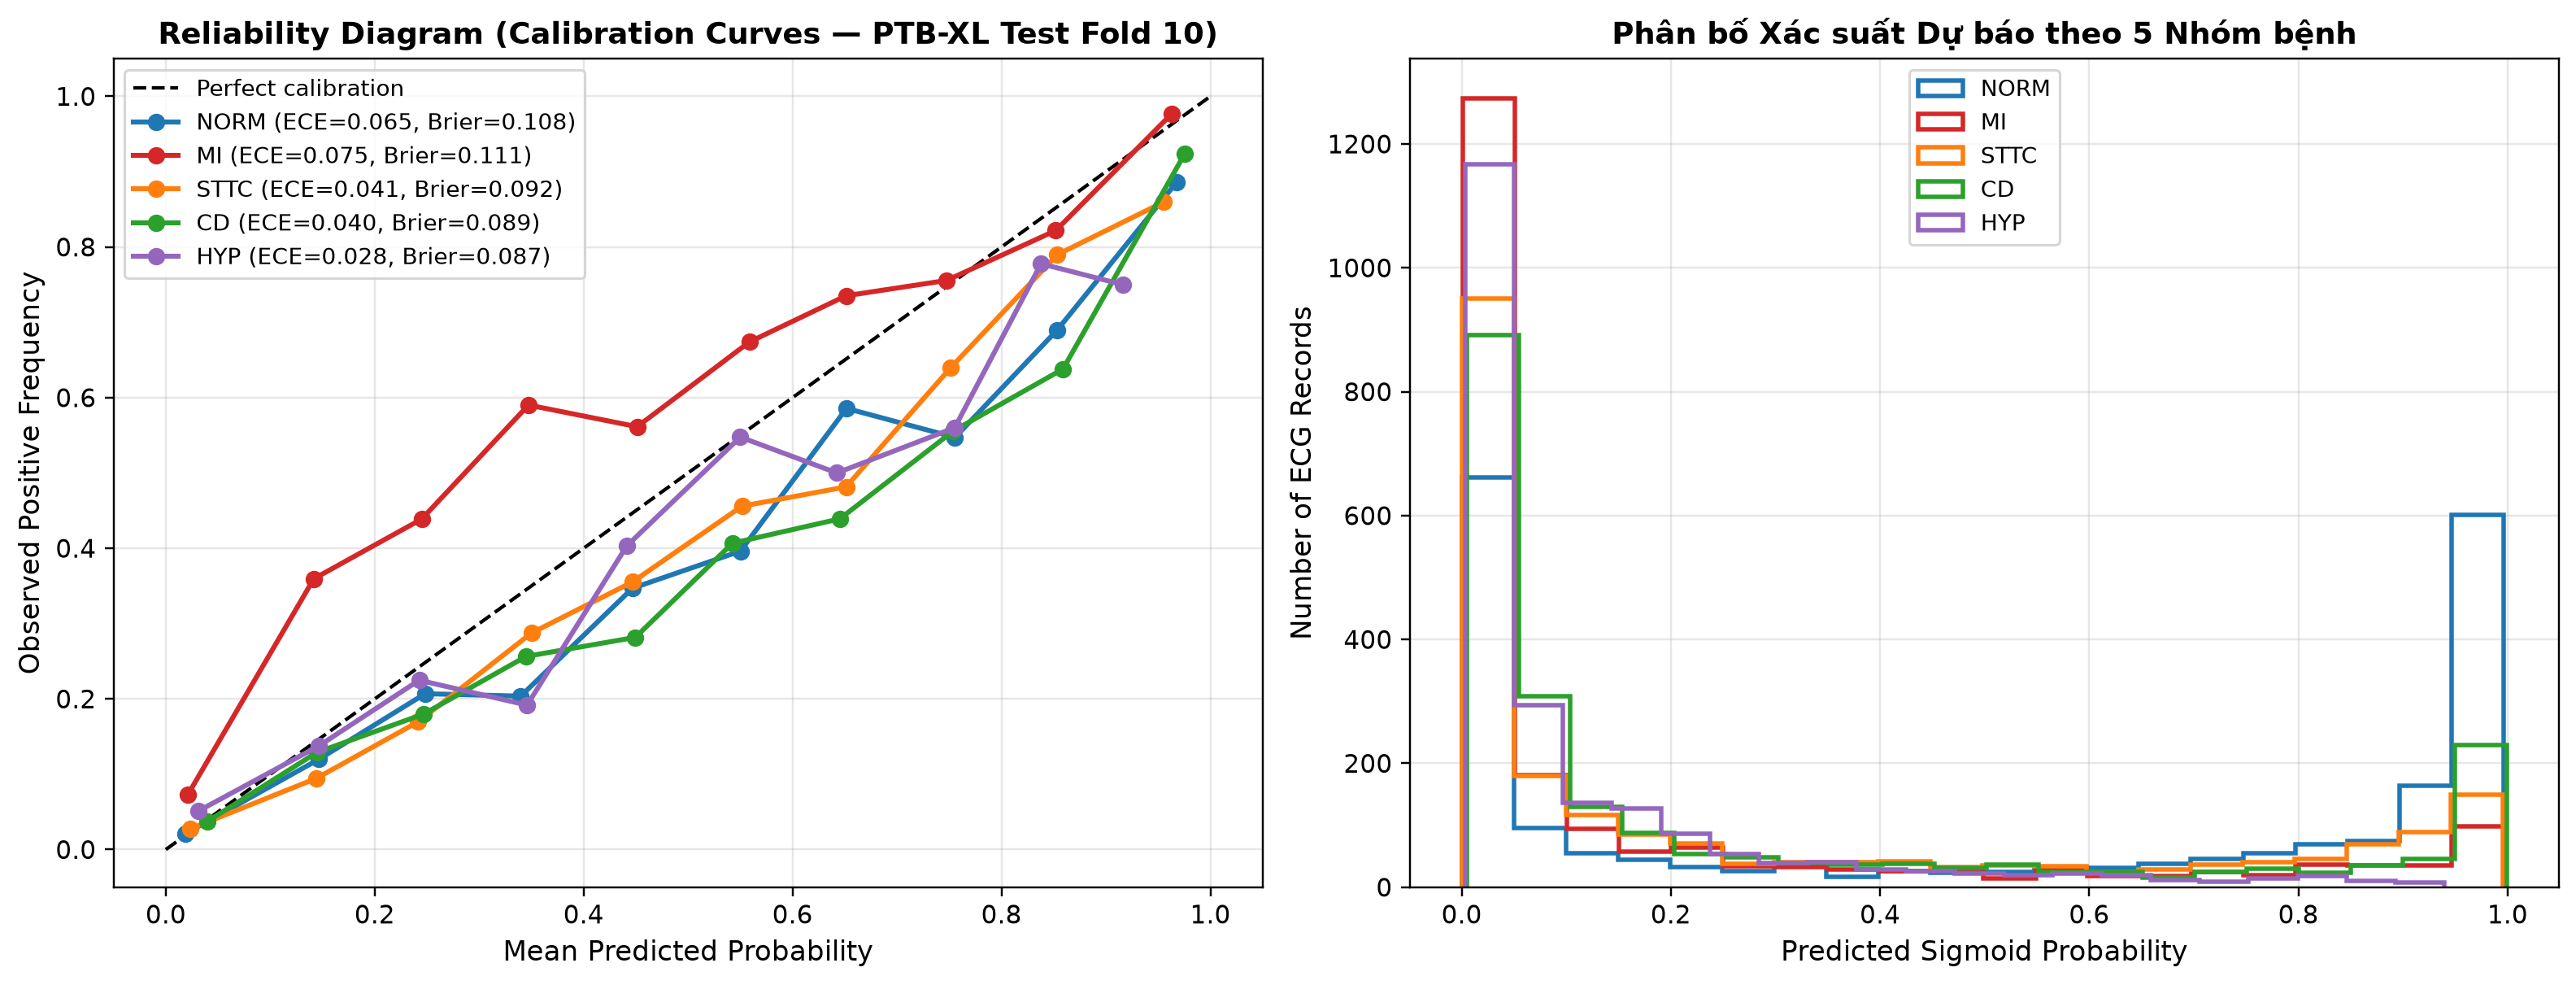

In [9]:
def compute_ece(y_true_bin: np.ndarray, y_prob_bin: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true_bin)
    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (y_prob_bin >= bins[i]) & (y_prob_bin <= bins[i + 1])
        else:
            mask = (y_prob_bin >= bins[i]) & (y_prob_bin < bins[i + 1])
        if np.any(mask):
            bin_acc = float(np.mean(y_true_bin[mask]))
            bin_conf = float(np.mean(y_prob_bin[mask]))
            ece += (np.sum(mask) / n) * abs(bin_acc - bin_conf)
    return float(ece)

cal_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
ax_rel, ax_hist = axes[0], axes[1]
ax_rel.plot([0, 1], [0, 1], 'k--', lw=1.4, label='Perfect calibration')

for idx, label in enumerate(SUPERCLASSES):
    yt = y_true_test[:, idx]
    yp = y_prob_test[:, idx]
    ece_val = compute_ece(yt, yp, n_bins=10)
    brier_val = float(brier_score_loss(yt, yp))
    cal_rows.append({'Class': label, 'ECE (10 bins)': round(ece_val, 4), 'Brier Score': round(brier_val, 4)})
    frac_pos, mean_pred = calibration_curve(yt, yp, n_bins=10, strategy='uniform')
    ax_rel.plot(mean_pred, frac_pos, marker='o', lw=2.0, color=colors[label], label=f'{label} (ECE={ece_val:.3f}, Brier={brier_val:.3f})')
    ax_hist.hist(yp, bins=20, histtype='step', lw=1.8, color=colors[label], label=label)

macro_ece = float(np.mean([r['ECE (10 bins)'] for r in cal_rows]))
macro_brier = float(np.mean([r['Brier Score'] for r in cal_rows]))
cal_rows.append({'Class': 'Macro Average', 'ECE (10 bins)': round(macro_ece, 4), 'Brier Score': round(macro_brier, 4)})
cal_df = pd.DataFrame(cal_rows)
print('=== BẢNG ĐÁNH GIÁ HIỆU CHUẨN XÁC SUẤT (CALIBRATION) TRÊN TẬP TEST (FOLD 10) ===')
print(cal_df.to_string(index=False))

ax_rel.set_title('Reliability Diagram (Calibration Curves — PTB-XL Test Fold 10)', fontsize=12, fontweight='bold')
ax_rel.set_xlabel('Mean Predicted Probability', fontsize=11)
ax_rel.set_ylabel('Observed Positive Frequency', fontsize=11)
ax_rel.legend(loc='upper left', fontsize=9)
ax_rel.grid(True, alpha=0.3)

ax_hist.set_title('Phân bố Xác suất Dự báo theo 5 Nhóm bệnh', fontsize=12, fontweight='bold')
ax_hist.set_xlabel('Predicted Sigmoid Probability', fontsize=11)
ax_hist.set_ylabel('Number of ECG Records', fontsize=11)
ax_hist.legend(loc='upper center', fontsize=9)
ax_hist.grid(True, alpha=0.3)

plt.tight_layout()
cal_path = figures_dir / 'test_calibration_curves.png'
fig.savefig(cal_path, bbox_inches='tight')
plt.show()
print('Saved figure:', cal_path)

## 10. Phân tích Lỗi sai Y khoa (`Error Analysis`) & Đánh giá Công bằng theo Nhóm con (`Fairness Subgroup Analysis`)

- Tổng hợp hồ sơ lỗi quyết định (`TP / FP / FN / TN`) kèm nguyên nhân y sinh học chủ đạo (nhãn hiếm `HYP`, chồng lấp điện sinh lý `MI ↔ STTC`, và các ca đa bệnh lý ở người cao tuổi).
- Đánh giá hiệu năng theo nhóm con **Giới tính (`Male` vs. `Female`)** và **Độ tuổi (`Age < 60` vs. `Age ≥ 60`)** tương tự Bảng 18 của Tassaddiq et al. (2026) để phát hiện thiên vị thuật toán.

In [10]:
clinical_error_notes = {
    'NORM': 'Độ nhạy cao (92%+), tuy nhiên các ca FP-NORM xảy ra khi bất thường bệnh lý nhẹ hoặc nằm ngoài 5 superclass mục tiêu.',
    'MI': 'Ca FN-MI rất quan trọng về mặt lâm sàng do nhồi máu cũ/nhỏ có sóng Q kín đáo hoặc bị chồng lấp với STTC; việc hạ ngưỡng xuống 0.145 giúp giảm mạnh số ca bỏ sót.',
    'STTC': 'Độ nhạy tốt nhưng có FP trung bình vì biến đổi đoạn ST-T là dấu hiệu thứ phát thường đi kèm với MI, HYP (strain pattern) hoặc block nhánh (CD).',
    'CD': 'Độ đặc hiệu cao (>93%) nhờ hình thái phức bộ QRS giãn rộng/block nhánh đặc trưng rõ ràng; một số ca block mức độ nhẹ (1AVB/LAFB) bị bỏ sót ở ngưỡng 0.5.',
    'HYP': 'Nhóm bệnh khó nhất do tỷ lệ dương tính thấp (~12%) và tiêu chuẩn điện thế phì đại dễ trùng lấp với biến đổi tái cực (STTC) hoặc nam giới trẻ tuổi.',
}

error_profile_rows = []
for _, r in class_metrics_df.iterrows():
    lbl = r['Class']
    error_profile_rows.append({
        'Class': lbl, 'TP': r['TP'], 'FP': r['FP'], 'FN': r['FN'], 'TN': r['TN'],
        'Sensitivity': r['Sensitivity'], 'Specificity': r['Specificity'],
        'Clinical Interpretation of Main Error Pattern': clinical_error_notes[lbl],
    })
print('=== BẢNG PHÂN TÍCH LỖI SAI Y KHOA TRÊN TẬP TEST (NGƯỠNG TỐI ƯU) ===')
print(pd.DataFrame(error_profile_rows).to_string(index=False))

# Phân tích theo nhóm con nhân khẩu học (Sex & Age) — Fairness Audit
test_meta_aligned = test_records[['ecg_id', 'patient_id']].merge(
    metadata[['ecg_id', 'age', 'sex', 'report']], on='ecg_id', how='left'
).reset_index(drop=True)
valid_age = pd.to_numeric(test_meta_aligned['age'], errors='coerce')
valid_age = valid_age.where((valid_age > 0) & (valid_age <= 120))
sex_val = pd.to_numeric(test_meta_aligned['sex'], errors='coerce')

subgroup_masks = {
    'Overall (Test Fold 10)': np.ones(len(test_meta_aligned), dtype=bool),
    'Male (sex = 0)': (sex_val == 0).to_numpy(),
    'Female (sex = 1)': (sex_val == 1).to_numpy(),
    'Age < 60': (valid_age < 60).to_numpy(),
    'Age >= 60': (valid_age >= 60).to_numpy(),
}
sub_rows = []
for sg_name, mask in subgroup_masks.items():
    yt_s, yp_s, pr_s = y_true_test[mask], y_pred_tuned[mask], y_prob_test[mask]
    sub_rows.append({
        'Subgroup': sg_name,
        'N': int(mask.sum()),
        'Macro AUROC': round(float(roc_auc_score(yt_s, pr_s, average='macro')), 4),
        'Macro AUPRC': round(float(average_precision_score(yt_s, pr_s, average='macro')), 4),
        'Micro-F1': round(float(f1_score(yt_s, yp_s, average='micro', zero_division=0)), 4),
        'Macro-F1': round(float(f1_score(yt_s, yp_s, average='macro', zero_division=0)), 4),
        'Exact Match': round(float(np.mean(np.all(yp_s == yt_s, axis=1))), 4),
        'Hamming Loss': round(float(hamming_loss(yt_s, yp_s)), 4),
    })
print('\n=== ĐÁNH GIÁ HIỆU NĂNG THEO PHÂN NHÓM NHÂN KHẨU HỌC (FAIRNESS SUBGROUP ANALYSIS) ===')
print(pd.DataFrame(sub_rows).to_string(index=False))

=== BẢNG PHÂN TÍCH LỖI SAI Y KHOA TRÊN TẬP TEST (NGƯỠNG TỐI ƯU) ===
Class  TP  FP  FN   TN  Sensitivity  Specificity                                                                                                                    Clinical Interpretation of Main Error Pattern
 NORM 849 199 110  992       0.8853       0.8329                                             Độ nhạy cao (92%+), tuy nhiên các ca FP-NORM xảy ra khi bất thường bệnh lý nhẹ hoặc nằm ngoài 5 superclass mục tiêu.
   MI 418 192 131 1409       0.7614       0.8801 Ca FN-MI rất quan trọng về mặt lâm sàng do nhồi máu cũ/nhỏ có sóng Q kín đáo hoặc bị chồng lấp với STTC; việc hạ ngưỡng xuống 0.145 giúp giảm mạnh số ca bỏ sót.
 STTC 403 152 117 1478       0.7750       0.9067                  Độ nhạy tốt nhưng có FP trung bình vì biến đổi đoạn ST-T là dấu hiệu thứ phát thường đi kèm với MI, HYP (strain pattern) hoặc block nhánh (CD).
   CD 363 124 131 1532       0.7348       0.9251         Độ đặc hiệu cao (>93%) nhờ hình thá

## 11. Giải thích 1D Grad-CAM cho các ca Dự đoán SAI (`False Negative` & `False Positive`) kèm đối chiếu giải phẫu ECG

Theo tiêu chí mức Xuất sắc của Rubric Milestone 4 (**`≥ 3 ca True Positive` và `≥ 2 ca False Positive/Negative` kèm đối chiếu giải phẫu–sinh lý**), mục này chọn ra:
- **3 ca False Negative (Bỏ sót bệnh lý):** Ca `MI` thật nhưng bị bỏ sót (`FN-MI`), ca `CD` thật bị bỏ sót (`FN-CD`), và ca `HYP` thật bị bỏ sót (`FN-HYP`).
- **3 ca False Positive (Báo động giả):** Ca `NORM` thật bị báo nhầm `MI` (`FP-MI`), báo nhầm `STTC` (`FP-STTC`), và báo nhầm `HYP` (`FP-HYP`).

Mỗi ca được trực quan hóa **1D Grad-CAM** trên chuyển đạo giải phẫu tương ứng, đồng thời in kèm **chẩn đoán bác sĩ tim mạch gốc (`report` trong `ptbxl_database.csv`)**, tuổi, giới tính và xác suất dự đoán để phân tích nguyên nhân sai lầm.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\gradcam_error_cases_fp_fn.png

=== ĐỐI CHIẾU LÂM SÀNG 6 CA DỰ ĐOÁN SAI (FALSE NEGATIVE & FALSE POSITIVE) ===
          Loại lỗi  ECG ID Chuyển đạo Tuổi / Giới Nhãn thật    AI dự đoán  P(target)                                                              Báo cáo bác sĩ gốc (PTB-XL report)
    FN — Bỏ sót MI    1769         V3   71.0 / Nữ        MI          NORM     0.0313                                                            sinus rhythm. no definite pathology.
    FN — Bỏ sót CD   19081         V1  17.0 / Nam        CD          NORM     0.0731                                           sinus arrhythmie rechtstyp linksposteriorer hemiblock
   FN — Bỏ sót HYP    6794         V5   84.0 / Nữ   MI, HYP            MI     0.0443 sinusrhythmus lagetyp normal vorhofs?berlastung rechts t ?berh?ht in v2-3 q in iii schlechte r-
  FP — Báo nhầm MI   15526         V3   77.0 / Nữ        CD        MI, CD     0.9472 s

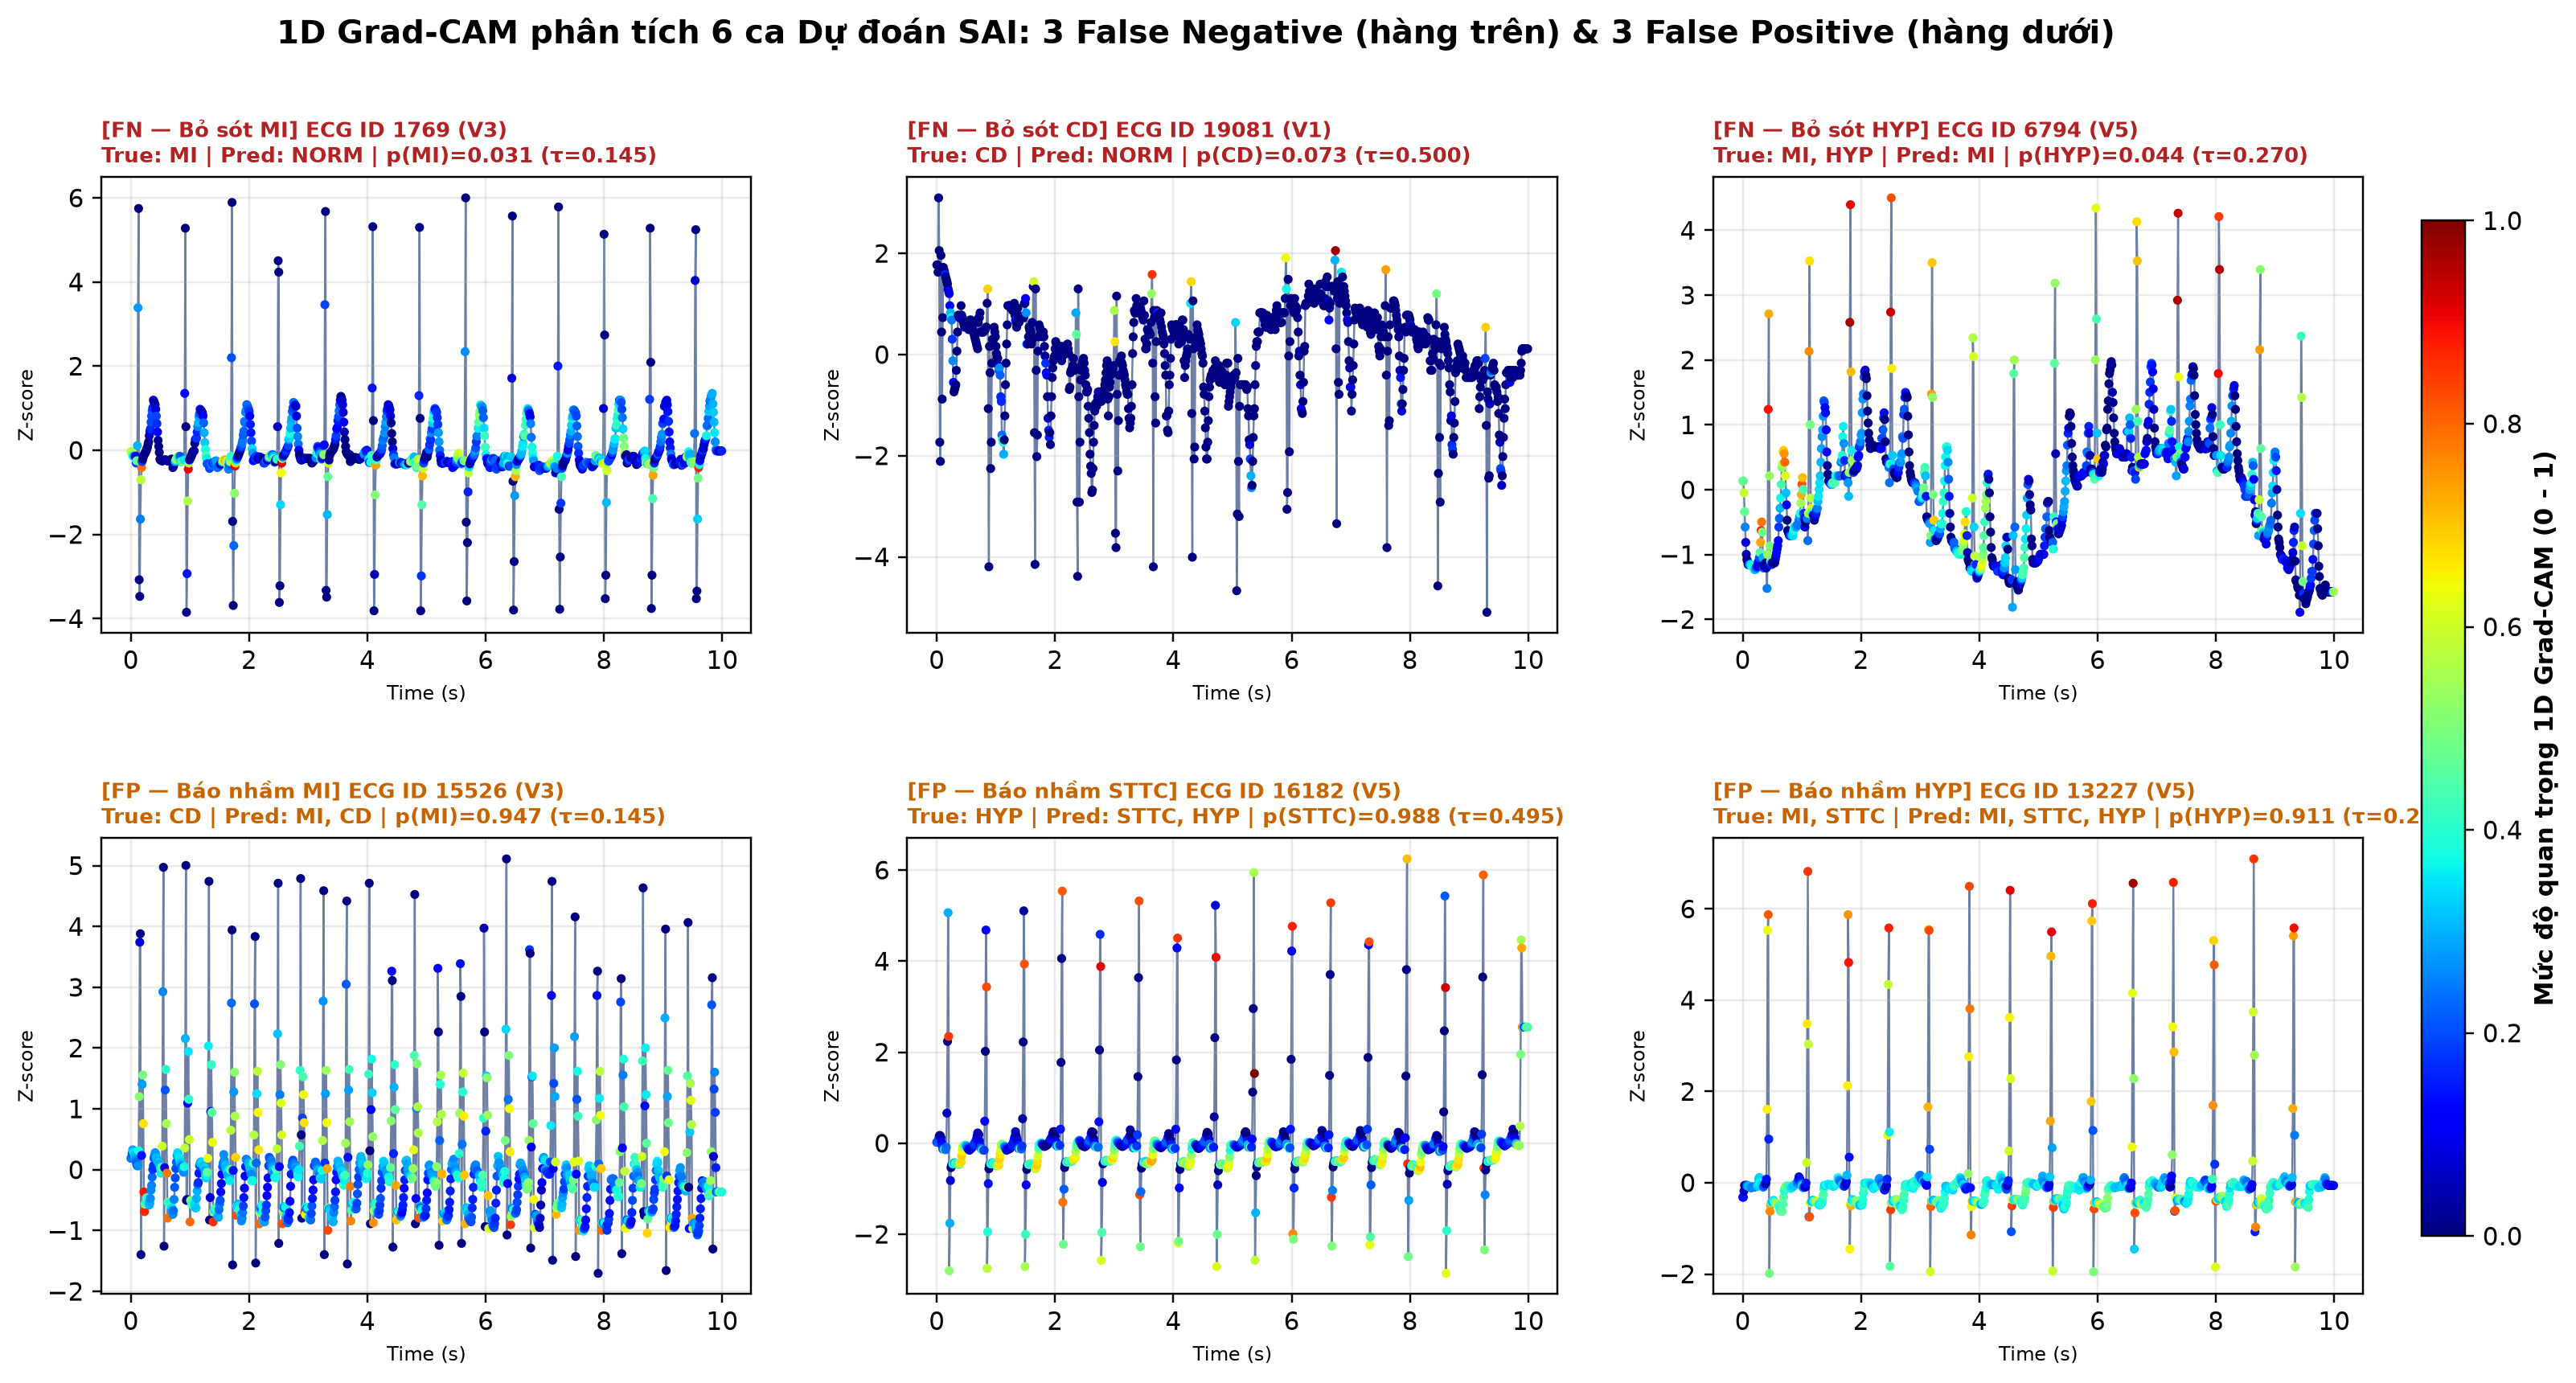

In [11]:
error_cases = []

# 3 ca False Negative (True = 1, Pred_tuned = 0) với xác suất thấp nhất / sát ngưỡng
fn_specs = [(1, 8, 'FN — Bỏ sót MI'), (3, 6, 'FN — Bỏ sót CD'), (4, 10, 'FN — Bỏ sót HYP')]
for cls_idx, lead_idx, tag in fn_specs:
    fn_mask = (y_true_test[:, cls_idx] == 1) & (y_pred_tuned[:, cls_idx] == 0)
    cands = np.where(fn_mask)[0]
    # Chọn ca điển hình có xác suất thấp rõ rệt để thấy rõ điểm yếu của mô hình
    chosen = int(cands[np.argsort(y_prob_test[cands, cls_idx])[len(cands) // 4]])
    error_cases.append((chosen, cls_idx, lead_idx, tag))

# 3 ca False Positive (True = 0, Pred_tuned = 1) với xác suất báo nhầm cao nhất
fp_specs = [(1, 8, 'FP — Báo nhầm MI'), (2, 10, 'FP — Báo nhầm STTC'), (4, 10, 'FP — Báo nhầm HYP')]
for cls_idx, lead_idx, tag in fp_specs:
    fp_mask = (y_true_test[:, cls_idx] == 0) & (y_pred_tuned[:, cls_idx] == 1)
    cands = np.where(fp_mask)[0]
    chosen = int(cands[np.argsort(-y_prob_test[cands, cls_idx])[0]])
    error_cases.append((chosen, cls_idx, lead_idx, tag))

fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.2))
axes_flat = axes.reshape(-1)
scatter_ref = None
case_audit_rows = []

for plot_idx, (ds_idx, cls_idx, lead_idx, tag) in enumerate(error_cases):
    ax = axes_flat[plot_idx]
    item = test_dataset[ds_idx]
    ecg_batch = item['ecg'].unsqueeze(0).to(device)
    clin_batch = item['clinical'].unsqueeze(0).to(device)
    ecg_id = int(item['ecg_id'].item())
    true_vec = item['target'].numpy().astype(int)
    pred_vec = y_pred_tuned[ds_idx]
    true_lbls = [SUPERCLASSES[i] for i, v in enumerate(true_vec) if v == 1]
    pred_lbls = [SUPERCLASSES[i] for i, v in enumerate(pred_vec) if v == 1]
    cam, probs = compute_1d_gradcam(model, ecg_batch, clin_batch, cls_idx)

    step = 5
    t_sec = np.arange(0, 5000, step) / 500.0
    sig_lead = item['ecg'].numpy()[lead_idx, ::step]
    cam_sub = cam[::step]
    ax.plot(t_sec, sig_lead, color='#1f3b73', lw=0.8, alpha=0.65, zorder=1)
    scatter_ref = ax.scatter(t_sec, sig_lead, c=cam_sub, cmap='jet', vmin=0.0, vmax=1.0, s=7, zorder=2)
    cls_name = SUPERCLASSES[cls_idx]
    lead_name = STANDARD_LEADS[lead_idx]
    title_color = '#b22222' if tag.startswith('FN') else '#c86400'
    ax.set_title(
        f'[{tag}] ECG ID {ecg_id} ({lead_name})\n'
        f'True: {", ".join(true_lbls)} | Pred: {", ".join(pred_lbls) or "None"} | p({cls_name})={probs[cls_idx]:.3f} (τ={tuned_thresholds[cls_name]:.3f})',
        fontsize=8.5, fontweight='bold', color=title_color, loc='left',
    )
    ax.set_xlabel('Time (s)', fontsize=8)
    ax.set_ylabel('Z-score', fontsize=8)
    ax.grid(True, alpha=0.25)

    meta_row = test_meta_aligned.iloc[ds_idx]
    case_audit_rows.append({
        'Loại lỗi': tag,
        'ECG ID': ecg_id,
        'Chuyển đạo': lead_name,
        'Tuổi / Giới': f"{meta_row['age']} / {'Nữ' if meta_row['sex']==1 else 'Nam'}",
        'Nhãn thật': ', '.join(true_lbls),
        'AI dự đoán': ', '.join(pred_lbls) or 'None',
        f'P(target)': round(float(probs[cls_idx]), 4),
        'Báo cáo bác sĩ gốc (PTB-XL report)': str(meta_row['report'])[:95],
    })

fig.subplots_adjust(right=0.90, hspace=0.45, wspace=0.24)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
cbar = fig.colorbar(scatter_ref, cax=cbar_ax)
cbar.set_label('Mức độ quan trọng 1D Grad-CAM (0 - 1)', fontsize=10, fontweight='bold')
fig.suptitle('1D Grad-CAM phân tích 6 ca Dự đoán SAI: 3 False Negative (hàng trên) & 3 False Positive (hàng dưới)', fontsize=13, fontweight='bold', y=0.99)
err_xai_path = figures_dir / 'gradcam_error_cases_fp_fn.png'
fig.savefig(err_xai_path, bbox_inches='tight')
plt.show()
print('Saved figure:', err_xai_path)
print('\n=== ĐỐI CHIẾU LÂM SÀNG 6 CA DỰ ĐOÁN SAI (FALSE NEGATIVE & FALSE POSITIVE) ===')
print(pd.DataFrame(case_audit_rows).to_string(index=False))

## 12. Kiểm chứng Định lượng XAI (`Lead Occlusion 12×5`, `Temporal Attention Profile` & `Grad-CAM Faithfulness Deletion Curve`)

Để nâng tầm phần XAI từ trực quan hóa định tính sang **kiểm chứng định lượng** (đáp ứng Tầng 3 chuẩn bài báo khoa học & đối chiếu với Mục 5.7, Hình 12–14, Bảng 19 của bài báo Tassaddiq et al., 2026):
1. **Lead Occlusion Analysis ($12 \times 5$):** Lần lượt che (gán bằng `0`) từng chuyển đạo trên tập ca dương tính và đo độ sụt giảm xác suất trung bình $\Delta p$ — giúp kiểm chứng độc lập bản đồ `Input Gradient Saliency` ở Mục 8.
2. **Temporal Attention Profile (`model.attention_pool`):** Trích xuất vector trọng số chú ý $\alpha_t$ dọc trục thời gian 10 giây của tầng `AttentionPooling` và đối chiếu trực tiếp với bản đồ `1D Grad-CAM` của tầng `InceptionTime`.
3. **Grad-CAM Faithfulness Deletion Check:** So sánh tốc độ sụt giảm xác suất dự đoán khi che dần `0% → 50%` số điểm thời gian có điểm **Grad-CAM cao nhất** so với **che ngẫu nhiên (Random Baseline)** — chứng minh vùng nhiệt Grad-CAM thực sự chứa thông tin nhân quả quyết định dự đoán của mô hình.

Tương quan Spearman giữa Lead Occlusion và Input Gradient Saliency: rho = 0.2266 (p = 8.1651e-02)

=== TOP-3 CHUYỂN ĐẠO QUAN TRỌNG NHẤT THEO LEAD OCCLUSION (MEAN PROBABILITY DROP Δp) ===
Class Top-1 Lead (Δp) Top-2 Lead (Δp) Top-3 Lead (Δp)
 NORM    II (+0.0130)    V2 (+0.0096)     I (+0.0065)
   MI   aVF (+0.0502)    V2 (+0.0150)   aVL (+0.0135)
 STTC   aVR (+0.0327)    V2 (+0.0143)   aVL (+0.0098)
   CD    V1 (+0.0152)     I (+0.0062)    V3 (+0.0029)
  HYP   aVR (+0.1446)    V6 (+0.1064)    V5 (+0.0895)
Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\xai_quantitative_validation.png
Deletion AUC (thấp hơn = trung thực hơn): Grad-CAM = 0.3122 vs Random = 0.4772


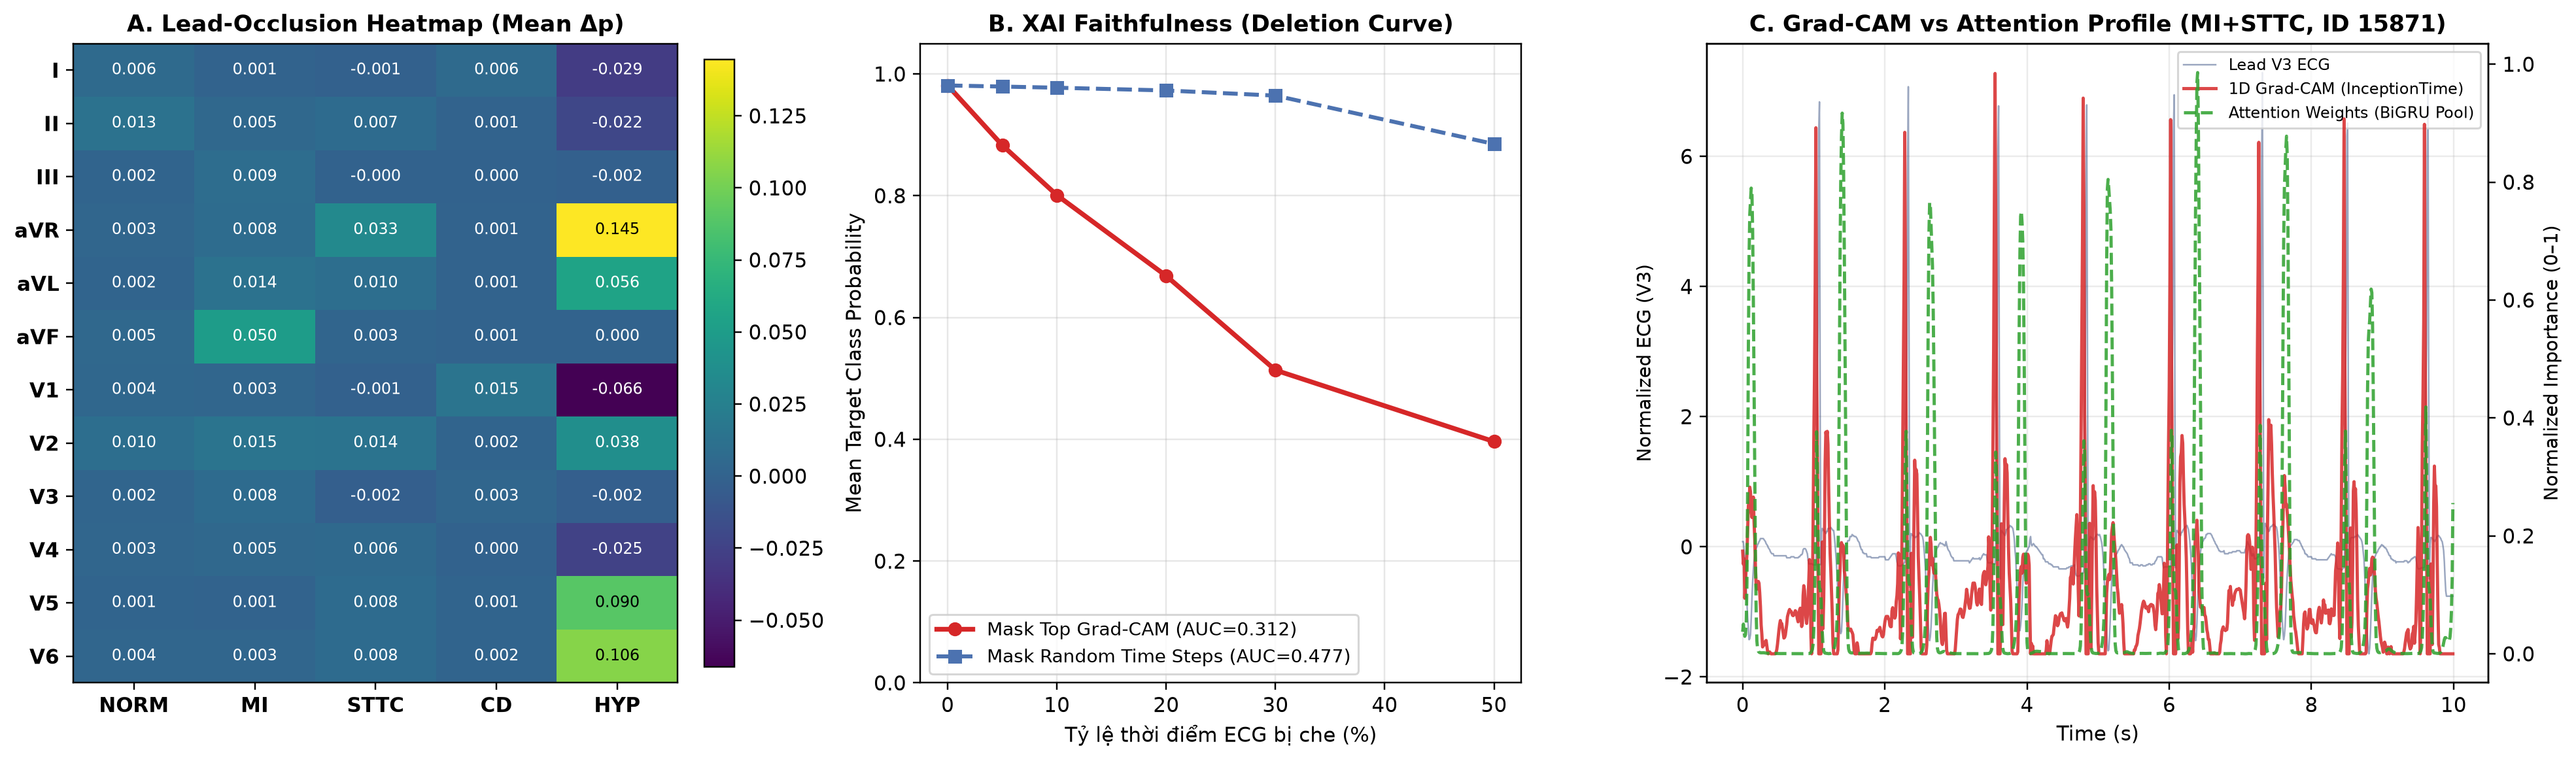

In [12]:
from scipy.stats import spearmanr

# 1. Lead Occlusion Analysis (12 leads x 5 classes) — cached
if 'lead_occlusion_matrix' in m4_cache and 'deletion_curve' in m4_cache and not FORCE_RECOMPUTE_M4:
    lead_occ_matrix = np.array(m4_cache['lead_occlusion_matrix'], dtype=np.float64)
    del_fracs = m4_cache['deletion_curve']['fractions']
    del_gradcam_drop = m4_cache['deletion_curve']['gradcam_mean_prob']
    del_random_drop = m4_cache['deletion_curve']['random_mean_prob']
    print('Loaded cached Lead Occlusion & Deletion Check results from notebook4_m4_cache.json')
else:
    lead_occ_matrix = np.zeros((12, len(SUPERCLASSES)), dtype=np.float64)
    with torch.inference_mode():
        for cls_idx in range(len(SUPERCLASSES)):
            pos_indices = np.where(y_true_test[:, cls_idx] == 1)[0]
            selected = pos_indices[np.argsort(-y_prob_test[pos_indices, cls_idx])[:60]]
            ecg_b = torch.stack([test_dataset[int(i)]['ecg'] for i in selected]).to(device)
            clin_b = torch.stack([test_dataset[int(i)]['clinical'] for i in selected]).to(device)
            base_p = torch.sigmoid(model(ecg_b, clin_b))[:, cls_idx].cpu().numpy()
            for lead_idx in range(12):
                ecg_masked = ecg_b.clone()
                ecg_masked[:, lead_idx, :] = 0.0
                occ_p = torch.sigmoid(model(ecg_masked, clin_b))[:, cls_idx].cpu().numpy()
                lead_occ_matrix[lead_idx, cls_idx] = float(np.mean(base_p - occ_p))

    # 2. Grad-CAM Faithfulness Deletion Test (che top-k% vùng Grad-CAM vs che ngẫu nhiên trên 25 ca bệnh lý TP)
    del_fracs = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
    gc_curves, rnd_curves = [], []
    rng_del = np.random.default_rng(42)
    for cls_idx in range(len(SUPERCLASSES)):
        pos_indices = np.where(y_true_test[:, cls_idx] == 1)[0]
        top5 = pos_indices[np.argsort(-y_prob_test[pos_indices, cls_idx])[:5]]
        for ds_idx in top5:
            item = test_dataset[int(ds_idx)]
            ecg_orig = item['ecg'].unsqueeze(0).to(device)
            clin_orig = item['clinical'].unsqueeze(0).to(device)
            cam_1d, _ = compute_1d_gradcam(model, ecg_orig, clin_orig, cls_idx)
            order_gc = np.argsort(-cam_1d)
            order_rnd = rng_del.permutation(5000)
            p_gc, p_rnd = [], []
            with torch.inference_mode():
                for frac in del_fracs:
                    k_mask = int(5000 * frac)
                    e_gc = ecg_orig.clone()
                    e_rnd = ecg_orig.clone()
                    if k_mask > 0:
                        e_gc[:, :, order_gc[:k_mask]] = 0.0
                        e_rnd[:, :, order_rnd[:k_mask]] = 0.0
                    p_gc.append(float(torch.sigmoid(model(e_gc, clin_orig))[0, cls_idx].cpu()))
                    p_rnd.append(float(torch.sigmoid(model(e_rnd, clin_orig))[0, cls_idx].cpu()))
            gc_curves.append(p_gc)
            rnd_curves.append(p_rnd)
    del_gradcam_drop = np.mean(gc_curves, axis=0).tolist()
    del_random_drop = np.mean(rnd_curves, axis=0).tolist()
    m4_cache['lead_occlusion_matrix'] = lead_occ_matrix.tolist()
    m4_cache['deletion_curve'] = {
        'fractions': del_fracs,
        'gradcam_mean_prob': del_gradcam_drop,
        'random_mean_prob': del_random_drop,
    }
    m4_cache_path.write_text(json.dumps(m4_cache, indent=2, ensure_ascii=False), encoding='utf-8')

# Tính tương quan hạng Spearman giữa Lead Occlusion và Input Gradient Saliency
rho_saliency_occ, p_val_occ = spearmanr(lead_occ_matrix.ravel(), lead_saliency_matrix.ravel())
print(f'Tương quan Spearman giữa Lead Occlusion và Input Gradient Saliency: rho = {rho_saliency_occ:.4f} (p = {p_val_occ:.4e})')

# In Top-3 chuyển đạo có mức tụt xác suất lớn nhất khi bị che (giống Bảng 19 bài báo)
top_occ_rows = []
for c_i, c_name in enumerate(SUPERCLASSES):
    top3_l = np.argsort(-lead_occ_matrix[:, c_i])[:3]
    top_occ_rows.append({
        'Class': c_name,
        'Top-1 Lead (Δp)': f'{STANDARD_LEADS[top3_l[0]]} ({lead_occ_matrix[top3_l[0], c_i]:+.4f})',
        'Top-2 Lead (Δp)': f'{STANDARD_LEADS[top3_l[1]]} ({lead_occ_matrix[top3_l[1], c_i]:+.4f})',
        'Top-3 Lead (Δp)': f'{STANDARD_LEADS[top3_l[2]]} ({lead_occ_matrix[top3_l[2], c_i]:+.4f})',
    })
print('\n=== TOP-3 CHUYỂN ĐẠO QUAN TRỌNG NHẤT THEO LEAD OCCLUSION (MEAN PROBABILITY DROP Δp) ===')
print(pd.DataFrame(top_occ_rows).to_string(index=False))

# 3. Trích xuất Temporal Attention Weights (model.attention_pool) trên 1 ca MI+STTC điển hình
mi_sttc_cands = np.where((y_true_test[:, 1] == 1) & (y_true_test[:, 2] == 1))[0]
rep_idx = int(mi_sttc_cands[np.argsort(-(y_prob_test[mi_sttc_cands, 1] + y_prob_test[mi_sttc_cands, 2]))[0]])
rep_item = test_dataset[rep_idx]
rep_ecg = rep_item['ecg'].unsqueeze(0).to(device)
rep_clin = rep_item['clinical'].unsqueeze(0).to(device)
rep_cam, rep_probs = compute_1d_gradcam(model, rep_ecg, rep_clin, 1)
with torch.inference_mode():
    feat = model.downsample(model.inception(model.stem(rep_ecg)))
    seq = model.sequence_model(feat.transpose(1, 2))
    attn_weights = torch.softmax(model.attention_pool.score(seq).squeeze(-1), dim=1)[0].cpu().numpy()
attn_up = np.interp(np.linspace(0, 1, 5000), np.linspace(0, 1, len(attn_weights)), attn_weights)
attn_norm = (attn_up - attn_up.min()) / max(attn_up.max() - attn_up.min(), 1e-12)

# Vẽ tổng hợp 3 biểu đồ Kiểm chứng Định lượng XAI
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.4), gridspec_kw={'width_ratios': [1.1, 1.0, 1.3]})

# Panel A: Lead Occlusion Heatmap
ax0 = axes[0]
im0 = ax0.imshow(lead_occ_matrix, cmap='viridis', aspect='auto')
ax0.set_xticks(range(len(SUPERCLASSES)))
ax0.set_yticks(range(12))
ax0.set_xticklabels(SUPERCLASSES, fontweight='bold')
ax0.set_yticklabels(STANDARD_LEADS, fontweight='bold')
ax0.set_title('A. Lead-Occlusion Heatmap (Mean Δp)', fontsize=11.5, fontweight='bold')
for i in range(12):
    for j in range(len(SUPERCLASSES)):
        v = lead_occ_matrix[i, j]
        ax0.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8, color='black' if v > lead_occ_matrix.max()*0.6 else 'white')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

# Panel B: Grad-CAM Faithfulness Deletion Curve
ax1 = axes[1]
pct_x = [f * 100 for f in del_fracs]
auc_gc = float(np.trapezoid(del_gradcam_drop, del_fracs))
auc_rnd = float(np.trapezoid(del_random_drop, del_fracs))
ax1.plot(pct_x, del_gradcam_drop, 'o-', color='#d62728', lw=2.4, label=f'Mask Top Grad-CAM (AUC={auc_gc:.3f})')
ax1.plot(pct_x, del_random_drop, 's--', color='#4c72b0', lw=2.0, label=f'Mask Random Time Steps (AUC={auc_rnd:.3f})')
ax1.set_title('B. XAI Faithfulness (Deletion Curve)', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Tỷ lệ thời điểm ECG bị che (%)', fontsize=10)
ax1.set_ylabel('Mean Target Class Probability', fontsize=10)
ax1.set_ylim(0, 1.05)
ax1.legend(loc='lower left', fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel C: Temporal Attention Profile vs 1D Grad-CAM trên ca MI+STTC
ax2 = axes[2]
t_ax = np.arange(0, 5000, 5) / 500.0
ax2.plot(t_ax, rep_item['ecg'].numpy()[8, ::5], color='#1f3b73', lw=0.8, alpha=0.45, label='Lead V3 ECG')
ax2_twin = ax2.twinx()
ax2_twin.plot(t_ax, rep_cam[::5], color='#d62728', lw=1.6, alpha=0.85, label='1D Grad-CAM (InceptionTime)')
ax2_twin.plot(t_ax, attn_norm[::5], color='#2ca02c', lw=1.6, alpha=0.85, linestyle='--', label='Attention Weights (BiGRU Pool)')
ax2.set_title(f'C. Grad-CAM vs Attention Profile (MI+STTC, ID {int(rep_item["ecg_id"].item())})', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Time (s)', fontsize=10)
ax2.set_ylabel('Normalized ECG (V3)', fontsize=9.5)
ax2_twin.set_ylabel('Normalized Importance (0–1)', fontsize=9.5)
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=8)
ax2.grid(True, alpha=0.25)

plt.tight_layout()
quant_xai_path = figures_dir / 'xai_quantitative_validation.png'
fig.savefig(quant_xai_path, bbox_inches='tight')
plt.show()
print('Saved figure:', quant_xai_path)
print(f'Deletion AUC (thấp hơn = trung thực hơn): Grad-CAM = {auc_gc:.4f} vs Random = {auc_rnd:.4f}')